<a href="https://colab.research.google.com/github/pri2007sha/climate-change-slm-dfa-classification/blob/main/AI_Based_Email_Spam_Detection_Automatic_Classification_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📧 AI-Based Email Spam Detection & Automatic Classification
**Run in Google Colab · No paid API · No access to your personal mailbox · Python**

### The story
You are a data analyst on the security team at **MailGuard**, a company whose staff receive thousands of emails every day.
Some are legitimate (**Ham**), some are unwanted or dangerous (**Spam**). Nobody can read them all. Your manager asks:

1. 📊 **What does our email data look like?** How many spam vs ham?
2. 🤖 **Can a machine learn to tell spam from ham?** Which algorithm is best?
3. 🔍 **Why** did the model decide that? Which words gave it away?
4. 🧩 **Can a simple rule-based machine (a Finite Automaton)** spot suspicious patterns — and how does it compare with the AI?
5. ⚡ **Can we classify a brand-new email the moment it arrives?**
6. 📈 **Can we send the results to Tableau** for a dashboard?

### Problem statement
Spam wastes time, spreads scams and phishing links, and hides important messages. Manual filtering does not scale.
We need an automatic system that reads an email and decides **Spam or Ham**, explains its decision, and produces data for a dashboard.

### Objectives
| # | Objective |
|---|---|
| 1 | Load and inspect a real public email corpus (SpamAssassin) and clean it (HTML, headers, duplicates, missing values) |
| 2 | Train and compare **TF-IDF + Logistic Regression** and **Multinomial Naive Bayes** (plus an *optional* DistilBERT) |
| 3 | Evaluate with accuracy, precision, recall, F1, confusion matrix and classification report — **without data leakage** |
| 4 | Build a **Deterministic Finite Automaton (DFA)** that detects suspicious *patterns* (rule-based, separate from the AI) |
| 5 | Explain predictions (real model evidence vs. rule-based heuristics) |
| 6 | Build an interactive "type an email → get a verdict" tool |
| 7 | Export 4 CSV files for a Tableau dashboard |

### The data
SpamAssassin Public Corpus — real emails stored as **raw email files** (headers + body). The notebook inspects the format first, then builds a table with the columns below.
You can alternatively use a **Kaggle CSV** (see Step 0 settings).

| email_id | source | label | subject | body | text_plain | clean_text | … features |
|---|---|---|---|---|---|---|---|

👉 The label (**Spam / Ham**) comes from the folder the email was stored in.

### How to run
Press **Shift + Enter** on each cell from top to bottom. Run **Step 0** first. Do **not** skip cells.
**Runtime ▸ Run all** also works, but the first time, run cell by cell so you can read each output.

## Step 0 — Load the tools and choose settings
Colab already has pandas, scikit-learn, seaborn and BeautifulSoup. Nothing to install for the main project.
The **settings block** below is the only place you might want to edit.

In [1]:
import os, re, io, sys, time, html, tarfile, zipfile, random, warnings, urllib.request
from email import policy
from email.parser import BytesParser
from email.utils import parsedate_to_datetime
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup, MarkupResemblesLocatorWarning

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore", category=MarkupResemblesLocatorWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# ───────────────────────── SETTINGS (edit here) ─────────────────────────
DATA_SOURCE     = "spamassassin"   # "spamassassin" (default)  or  "kaggle_csv"
KAGGLE_CSV      = "emails.csv"     # only used when DATA_SOURCE = "kaggle_csv"
TEXT_COL        = None             # Kaggle CSV: leave None to auto-detect the email-text column
LABEL_COL       = None             # Kaggle CSV: leave None to auto-detect the spam/ham column
RUN_TRANSFORMER = False            # True = also train DistilBERT in Step 7 (best with GPU)
MAX_TEXT_CHARS  = 20000            # long emails are cut to this many characters
SEED            = 42
# ─────────────────────────────────────────────────────────────────────────

random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid")
COLORS = {"Ham": "#2e9d5b", "Spam": "#d64545"}
print("✔ Tools ready")
print("  Data source :", DATA_SOURCE)
print("  DistilBERT  :", "ON (optional)" if RUN_TRANSFORMER else "OFF (main project runs without it)")

✔ Tools ready
  Data source : spamassassin
  DistilBERT  : OFF (main project runs without it)


## Step 1 — Get the dataset
### Option A (default): automatic download of the SpamAssassin corpus
The corpus is a set of `.tar.bz2` archives. Folder names tell us the label:

| Archive contains | Label |
|---|---|
| `easy_ham`, `easy_ham_2`, `hard_ham` | **Ham** (legitimate; *hard* ham is deliberately spam-like) |
| `spam`, `spam_2` | **Spam** |

Run the cell. It first looks for archives already in Colab, then tries to download the missing ones.
If the download is blocked, it will **ask you to upload** the archives yourself (download them from
<https://spamassassin.apache.org/old/publiccorpus/> to your computer first — see the Dataset Preparation Guide).

### Option B: Kaggle CSV
Set `DATA_SOURCE = "kaggle_csv"` in Step 0, re-run Step 0, then run this cell — it will ask you to upload your CSV.

In [2]:
BASE_URL = "https://spamassassin.apache.org/old/publiccorpus/"
FALLBACK_ARCHIVES = ["20030228_easy_ham.tar.bz2", "20030228_easy_ham_2.tar.bz2", "20030228_hard_ham.tar.bz2",
                     "20030228_spam.tar.bz2", "20030228_spam_2.tar.bz2", "20050311_spam_2.tar.bz2"]
WANTED_PREFIXES = ("20030228_", "20050311_")      # newer, de-duplicated releases

def http_get(url, timeout=60):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (Colab student project)"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()

def find_archive_names():
    try:
        page = http_get(BASE_URL, timeout=20).decode("utf-8", errors="ignore")
        names = sorted(set(re.findall(r'href="([^"/]+\.tar\.bz2)"', page)))
        names = [n for n in names if n.startswith(WANTED_PREFIXES)]
        if names:
            return names
    except Exception as e:
        print("  (could not read the corpus index page:", type(e).__name__, ") → using the built-in file list")
    return FALLBACK_ARCHIVES

def prepare_spamassassin():
    names = find_archive_names()
    print("Archives we want:", ", ".join(names))
    for n in names:
        if os.path.exists(n):
            print(f"  ✔ {n} already here"); continue
        try:
            data = http_get(BASE_URL + n)
            with open(n, "wb") as f: f.write(data)
            print(f"  ✔ downloaded {n}  ({len(data)/1e6:.1f} MB)")
        except Exception as e:
            print(f"  ✖ could not download {n}: {type(e).__name__}")
    have = sorted(f for f in os.listdir(".") if f.endswith(".tar.bz2"))
    has_ham  = any("ham"  in f for f in have)
    has_spam = any("spam" in f for f in have)
    if not (has_ham and has_spam):
        print("\n⚠ Need at least one *ham* archive and one *spam* archive. Please upload them now.")
        try:
            from google.colab import files
            files.upload()
        except ImportError:
            print("   (not running in Colab — put the .tar.bz2 files next to this notebook)")
        have = sorted(f for f in os.listdir(".") if f.endswith(".tar.bz2"))
    return have

def prepare_kaggle():
    if not os.path.exists(KAGGLE_CSV):
        try:
            from google.colab import files
            print(f"Upload your Kaggle CSV (it will be used as '{KAGGLE_CSV}' — rename if needed).")
            up = files.upload()
            if up and KAGGLE_CSV not in up:
                first = list(up)[0]; os.rename(first, KAGGLE_CSV); print(f"  renamed {first} → {KAGGLE_CSV}")
        except ImportError:
            pass
    print("✔ CSV found" if os.path.exists(KAGGLE_CSV) else f"✖ Please upload a CSV and make sure it is called {KAGGLE_CSV}")

if DATA_SOURCE == "spamassassin":
    ARCHIVE_FILES = prepare_spamassassin()
    print("\nArchives ready:", ARCHIVE_FILES)
else:
    prepare_kaggle()

Archives we want: 20030228_easy_ham.tar.bz2, 20030228_easy_ham_2.tar.bz2, 20030228_hard_ham.tar.bz2, 20030228_spam.tar.bz2, 20030228_spam_2.tar.bz2, 20050311_spam_2.tar.bz2
  ✔ downloaded 20030228_easy_ham.tar.bz2  (1.6 MB)
  ✔ downloaded 20030228_easy_ham_2.tar.bz2  (1.1 MB)
  ✔ downloaded 20030228_hard_ham.tar.bz2  (1.0 MB)
  ✔ downloaded 20030228_spam.tar.bz2  (1.2 MB)
  ✔ downloaded 20030228_spam_2.tar.bz2  (2.1 MB)
  ✔ downloaded 20050311_spam_2.tar.bz2  (2.1 MB)

Archives ready: ['20030228_easy_ham.tar.bz2', '20030228_easy_ham_2.tar.bz2', '20030228_hard_ham.tar.bz2', '20030228_spam.tar.bz2', '20030228_spam_2.tar.bz2', '20050311_spam_2.tar.bz2']


✅ You should see a list of archives marked ✔. If you see ✖ for every file, your Colab cannot reach the website — follow the upload prompt instead.

## Step 2 — Read the raw emails and look at their format
We read each file **as bytes** (emails can contain odd characters) and remember its **folder** and **label**.
We do **not** assume a format — we look first.

In [3]:
def label_from_folder(folder):
    f = folder.lower()
    if "ham" in f:  return "Ham"
    if "spam" in f: return "Spam"
    return None

def load_spamassassin(archive_files):
    recs = []
    for arc in archive_files:
        try:
            with tarfile.open(arc, "r:bz2") as tar:
                for m in tar:
                    if not m.isfile(): continue
                    parts = m.name.split("/")
                    fname = parts[-1]
                    if fname == "cmds" or fname.startswith("."):      # index files, not emails
                        continue
                    stem = os.path.basename(arc).replace(".tar.bz2", "")      # e.g. 20030228_easy_ham
                    folder = parts[-2] if len(parts) > 1 else stem
                    lab = label_from_folder(folder) or label_from_folder(stem)
                    if lab is None: continue
                    recs.append({"email_id": f"{stem}/{fname}", "source": stem,
                                 "label": lab, "raw": tar.extractfile(m).read()})
        except (tarfile.ReadError, EOFError, OSError) as e:
            print(f"✖ Could not open {arc}: {e}\n  → The file may be incomplete or not a real .tar.bz2 (e.g. an HTML page saved by mistake). Re-download it.")
    return recs

def load_kaggle_csv(path):
    for enc in ("utf-8", "latin-1"):
        try:
            raw_df = pd.read_csv(path, encoding=enc); break
        except UnicodeDecodeError:
            continue
    print("CSV columns:", list(raw_df.columns), "| rows:", len(raw_df))
    label_col, text_col = LABEL_COL, TEXT_COL
    if label_col is None:
        ok = {"spam","ham","0","1","not spam","legitimate","1.0","0.0"}
        for c in raw_df.columns:
            vals = set(raw_df[c].dropna().astype(str).str.strip().str.lower().unique())
            if 0 < len(vals) <= 4 and vals <= ok:
                label_col = c; break
    if text_col is None:
        cand = [c for c in raw_df.columns if c != label_col and not pd.api.types.is_numeric_dtype(raw_df[c])]
        text_col = max(cand, key=lambda c: raw_df[c].astype(str).str.len().mean()) if cand else None
    if label_col is None or text_col is None:
        raise ValueError(f"Could not auto-detect columns. Set TEXT_COL and LABEL_COL in Step 0. Columns: {list(raw_df.columns)}")
    print(f"Using text column = '{text_col}', label column = '{label_col}'")
    print("Label values found:", raw_df[label_col].value_counts(dropna=False).to_dict())
    def to_label(v):
        s = str(v).strip().lower()
        if s in ("spam","1","1.0"): return "Spam"
        if s in ("ham","0","0.0","not spam","legitimate"): return "Ham"
        return None
    recs = []
    for i, (t, l) in enumerate(zip(raw_df[text_col], raw_df[label_col])):
        lab = to_label(l)
        if lab is None or pd.isna(t): continue
        recs.append({"email_id": f"csv/{i}", "source": "csv", "label": lab, "raw": str(t).encode("utf-8", errors="replace")})
    return recs

records = load_spamassassin(ARCHIVE_FILES) if DATA_SOURCE == "spamassassin" else load_kaggle_csv(KAGGLE_CSV)
raw_df = pd.DataFrame(records)
print(f"\n✔ Read {len(raw_df)} raw emails")
raw_df.groupby(["source", "label"]).size().rename("emails").reset_index()


✔ Read 7443 raw emails


,source,label,emails
0,20030228_easy_ham,Ham,2500
1,20030228_easy_ham_2,Ham,1400
2,20030228_hard_ham,Ham,250
3,20030228_spam,Spam,500
4,20030228_spam_2,Spam,1397
5,20050311_spam_2,Spam,1396


### 🔎 What does a raw email look like?
A raw email has **headers** (From, To, Subject, Received…) then a blank line, then the **body**. The body may be plain text, HTML, or both.

In [4]:
sample = raw_df.sample(1, random_state=SEED).iloc[0]
print("Folder:", sample["source"], "| Label:", sample["label"], "| Size:", len(sample["raw"]), "bytes\n")
print(sample["raw"].decode("utf-8", errors="replace")[:1500])
print("\n" + "─"*70)
sizes = raw_df["raw"].map(len)          # (.map(len) works on bytes in every pandas version)
print("Raw size (bytes) — min / median / max:", sizes.min(), "/", int(sizes.median()), "/", sizes.max())

Folder: 20050311_spam_2 | Label: Spam | Size: 2129 bytes

From Lisandra2283348@jrnl.ut.ee  Tue Aug  6 12:52:28 2002
Return-Path: <Lisandra2283348@jrnl.ut.ee>
Delivered-To: yyyy@localhost.netnoteinc.com
Received: from localhost (localhost [127.0.0.1])
	by phobos.labs.netnoteinc.com (Postfix) with ESMTP id ED04144118
	for <jm@localhost>; Tue,  6 Aug 2002 07:18:41 -0400 (EDT)
Received: from phobos [127.0.0.1]
	by localhost with IMAP (fetchmail-5.9.0)
	for jm@localhost (single-drop); Tue, 06 Aug 2002 12:18:41 +0100 (IST)
Received: from mail.ksilbo.co.kr ([211.183.223.230]) by
    dogma.slashnull.org (8.11.6/8.11.6) with SMTP id g73MLJv29787;
    Sat, 3 Aug 2002 23:21:19 +0100
Received: from olemail.com (unverified [62.110.39.186]) by
    mail.ksilbo.co.kr (EMWAC SMTPRS 0.83) with SMTP id
    <B0001052085@mail.ksilbo.co.kr>; Sun, 04 Aug 2002 07:26:40 +0900
Message-Id: <00004d5e57e3$0000103c$00005a82@dbzmail.com>
To: <I16102@arsenal.co.uk>
From: "Alejandra" <Lisandra2283348@jrnl.ut.ee>
Subje

### ⚠ Two important observations (read these!)
1. **Headers can leak the answer.** In a public corpus, spam and ham were collected from different places, so header lines like `Received:` or `Message-ID:` may differ for reasons that have nothing to do with the *content*. A model that learns those would look brilliant here and fail on real mail. **We will train only on the Subject + visible body text, never on raw headers.**
2. **HTML hides the text.** Many spam emails are HTML — tags like `<font>` would become "words". We strip the tags, keep the visible text, and keep the **link addresses** (they matter for spam).

## Step 3 — Parse and clean the emails (preprocessing)
For every email we:
1. Parse the headers/body with Python's built-in `email` library (handles multipart, base64, odd encodings).
2. Take **Subject + body** (prefer plain text; if only HTML exists, strip the tags with BeautifulSoup).
3. Collect link addresses (`href`) so URLs are not lost when HTML is stripped.
4. Build two texts:
   * `text_plain` — readable text with URLs intact (used by the DFA, the optional DistilBERT, and display)
   * `clean_text` — lower-case, URLs → `urltoken`, e-mail addresses → `emailaddr`, money → `moneytoken`, numbers → `numtoken`, punctuation removed (used by TF-IDF models)
5. Calculate simple features (length, URL count, HTML flag, exclamation marks, CAPITALS ratio) for the analysis charts.

In [5]:
URL_RE   = re.compile(r"(?:https?://|www\.)[^\s<>\"')\]]+", re.I)
EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")
MONEY_RE = re.compile(r"[$£€]\s?\d[\d,]*(?:\.\d+)?")
HEADER_STARTS = ("from ", "from:", "return-path:", "received:", "delivered-to:", "subject:",
                 "to:", "date:", "message-id:", "mime-version:", "content-type:")

def looks_like_rfc822(head_text):
    lines = [l.lower() for l in head_text.splitlines()[:20]]
    return sum(any(l.startswith(h) for h in HEADER_STARTS) for l in lines) >= 2

def html_to_text(markup):
    soup = BeautifulSoup(markup, "html.parser")
    hrefs = [a.get("href") for a in soup.find_all("a") if a.get("href")]
    for t in soup(["script", "style", "head"]):
        t.decompose()
    return soup.get_text(" "), hrefs

def safe_part_text(part):
    try:
        return part.get_content()
    except Exception:
        payload = part.get_payload(decode=True) or b""
        return payload.decode("utf-8", errors="replace")

def extract_email(raw_bytes):
    # Returns subject, body (visible text), hrefs, has_html, date.  Never raises.
    head = raw_bytes[:2500].decode("utf-8", errors="ignore")
    subject, body, hrefs, has_html, date = "", "", [], False, pd.NaT
    try:
        if looks_like_rfc822(head):
            msg = BytesParser(policy=policy.default).parsebytes(raw_bytes)
            try:    subject = str(msg.get("subject", "") or "")
            except Exception: subject = ""
            try:
                d = parsedate_to_datetime(str(msg.get("date", "")))
                d = d.replace(tzinfo=None) if d is not None else pd.NaT
                date = d if (d is not pd.NaT and 1990 <= d.year <= datetime.now().year) else pd.NaT
            except Exception:
                date = pd.NaT
            plains, htmls = [], []
            for part in msg.walk():
                if part.is_multipart(): continue
                ctype = part.get_content_type()
                if ctype == "text/plain":  plains.append(safe_part_text(part))
                elif ctype == "text/html": htmls.append(safe_part_text(part))
            has_html = len(htmls) > 0
            html_text = ""
            for h in htmls:
                t, hr = html_to_text(h); html_text += " " + t; hrefs += hr
            body = " ".join(plains).strip() or html_text.strip()
        else:
            text = raw_bytes.decode("utf-8", errors="replace")
            m = re.match(r"\s*subject:\s*(.+)", text, re.I)
            if m:
                subject = m.group(1).strip(); text = text[m.end():]
            if re.search(r"<\s*(html|body|div|p|a|table|br|font)\b", text, re.I):
                has_html = True
                body, hrefs = html_to_text(text)
            else:
                body = text
    except Exception:
        body = raw_bytes.decode("utf-8", errors="replace")
    return {"subject": subject.strip(), "body": body.strip(), "hrefs": hrefs, "has_html": has_html, "date": date}

def build_plain(rec):
    txt = (rec["subject"] + "\n" + rec["body"] + "\n" + " ".join(rec["hrefs"])).strip()
    return re.sub(r"[ \t\r\f\v]+", " ", txt)[:MAX_TEXT_CHARS]

def clean_for_model(text):
    t = text.lower()
    t = URL_RE.sub(" urltoken ", t)
    t = EMAIL_RE.sub(" emailaddr ", t)
    t = MONEY_RE.sub(" moneytoken ", t)
    t = re.sub(r"\d+", " numtoken ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

# ---- quick demonstration on one tiny example ----
demo = extract_email(b"From: a@b.com\nSubject: WIN $500 now!!!\nContent-Type: text/html\n\n<html><body><p>Click <a href='http://x.example/win'>here</a> to claim 100% FREE cash</p></body></html>")
print("subject   :", demo["subject"]); print("body      :", demo["body"]); print("hrefs     :", demo["hrefs"]); print("has_html  :", demo["has_html"])
print("clean_text:", clean_for_model(build_plain(demo)))

subject   : WIN $500 now!!!
body      : Click  here  to claim 100% FREE cash
hrefs     : ['http://x.example/win']
has_html  : True
clean_text: win moneytoken now click here to claim numtoken free cash urltoken


👆 Notice the HTML tags are gone, the link survived, and `$500` became `moneytoken`.
Now we apply this to **every** email. This may take 30–90 seconds for ~8,000 emails.

In [6]:
t0 = time.time()
parsed = [extract_email(b) for b in raw_df["raw"]]
df = raw_df.drop(columns=["raw"]).copy()
df["subject"]    = [p["subject"] for p in parsed]
df["body"]       = [p["body"] for p in parsed]
df["has_html"]   = [p["has_html"] for p in parsed]
df["email_date"] = pd.to_datetime([p["date"] for p in parsed], errors="coerce")
df["text_plain"] = [build_plain(p) for p in parsed]
df["clean_text"] = df["text_plain"].apply(clean_for_model)

# simple measurable features (for charts; NOT given to the models)
df["char_len"]    = df["text_plain"].str.len()
df["word_count"]  = df["clean_text"].str.split().str.len()
df["url_count"]   = df["text_plain"].apply(lambda t: len(set(URL_RE.findall(t))))
df["exclam_count"]= df["text_plain"].str.count("!")
df["caps_ratio"]  = df["text_plain"].apply(lambda t: sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t))).round(4)
df["y"]           = (df["label"] == "Spam").astype(int)      # 1 = Spam (the class we want to catch)
print(f"✔ Parsed {len(df)} emails in {time.time()-t0:.0f}s")
df[["email_id", "label", "subject", "word_count", "url_count", "has_html"]].head(8)

✔ Parsed 7443 emails in 41s


,email_id,label,subject,word_count,url_count,has_html
0,20030228_easy_ham/00001.7c53336b37003a9286aba5...,Ham,Re: New Sequences Window,256,1,False
1,20030228_easy_ham/00002.9c4069e25e1ef370c078db...,Ham,[zzzzteana] RE: Alexander,114,2,False
2,20030228_easy_ham/00003.860e3c3cee1b42ead714c5...,Ham,[zzzzteana] Moscow bomber,257,2,False
3,20030228_easy_ham/00004.864220c5b6930b209cc287...,Ham,[IRR] Klez: The Virus That Won't Die,175,2,False
4,20030228_easy_ham/00005.bf27cdeaf0b8c4647ecd61...,Ham,Re: [zzzzteana] Nothing like mama used to make,150,3,False
5,20030228_easy_ham/00006.253ea2f9a9cc36fa0b1129...,Ham,Re: [zzzzteana] Nothing like mama used to make,106,2,False
6,20030228_easy_ham/00007.37a8af848caae585af4fe3...,Ham,[zzzzteana] Playboy wants to go out with a bang,212,2,False
7,20030228_easy_ham/00008.5891548d921601906337dc...,Ham,Re: [zzzzteana] Nothing like mama used to make,178,4,False


## Step 4 — Data quality: missing values and duplicates
Real data is messy. We check four things:
* **Empty emails** (nothing readable left after cleaning)
* **Missing subjects**
* **Exact duplicates** — the same text twice. If one copy lands in training and the other in testing, the model "remembers" it instead of learning → **data leakage**. So we remove duplicates *before* splitting.
* **Conflicting labels** — identical text labelled both Spam and Ham → unreliable, removed.

In [7]:
n0 = len(df)
print("Emails before cleaning       :", n0)
print("Missing / empty subject      :", int((df["subject"].str.len() == 0).sum()))
print("Empty body                   :", int((df["body"].str.len() == 0).sum()))
too_short = df["clean_text"].str.split().str.len().fillna(0) < 3
print("Fewer than 3 words after clean:", int(too_short.sum()))
df = df[~too_short].copy()

conf = df.groupby("clean_text")["label"].nunique()
conflict_texts = set(conf[conf > 1].index)
print("Texts with conflicting labels :", len(conflict_texts))
df = df[~df["clean_text"].isin(conflict_texts)].copy()

dup_mask = df.duplicated(subset="clean_text", keep="first")
print("Exact duplicate emails removed:", int(dup_mask.sum()))
df = df[~dup_mask].copy().reset_index(drop=True)

print(f"\n✔ Emails after cleaning: {len(df)}  (removed {n0-len(df)})")
print(df["label"].value_counts().to_string())

Emails before cleaning       : 7443
Missing / empty subject      : 30
Empty body                   : 49
Fewer than 3 words after clean: 16
Texts with conflicting labels : 0
Exact duplicate emails removed: 1579

✔ Emails after cleaning: 5848  (removed 1595)
label
Ham     4093
Spam    1755


## Step 5 — Exploratory Data Analysis (EDA)
### 5a. Dataset overview

In [8]:
overview = pd.DataFrame({
    "Emails": [len(df)],
    "Ham": [(df.label == "Ham").sum()],
    "Spam": [(df.label == "Spam").sum()],
    "Spam %": [round(100 * (df.label == "Spam").mean(), 1)],
    "Sources (folders)": [df.source.nunique()],
    "Median words": [int(df.word_count.median())],
    "With HTML %": [round(100 * df.has_html.mean(), 1)],
    "With ≥1 URL %": [round(100 * (df.url_count > 0).mean(), 1)],
})
display(overview.astype(object).T.rename(columns={0: "value"}))

print("\nColumns we now have:")
display(pd.DataFrame({"column": df.columns, "type": df.dtypes.astype(str).values,
                      "example": [str(df[c].iloc[0])[:50].replace("\n", " ") for c in df.columns]}))

,value
Emails,5848
Ham,4093
Spam,1755
Spam %,30.0
Sources (folders),5
Median words,158
With HTML %,19.4
With ≥1 URL %,85.9



Columns we now have:


,column,type,example
0,email_id,object,20030228_easy_ham/00001.7c53336b37003a9286aba5...
1,source,object,20030228_easy_ham
2,label,object,Ham
3,subject,object,Re: New Sequences Window
4,body,object,"Date: Wed, 21 Aug 2002 10:54:46 -0500 ..."
5,has_html,bool,False
6,email_date,datetime64[ns],2002-08-22 18:26:25
7,text_plain,object,"Re: New Sequences Window Date: Wed, 21 Aug 200..."
8,clean_text,object,re new sequences window date wed numtoken aug ...
9,char_len,int64,1599


### 5b. Class distribution — how many Spam vs Ham?
If one class is much bigger, a lazy model can look accurate by always guessing the big class — so we will use **precision, recall and F1**, not accuracy alone.

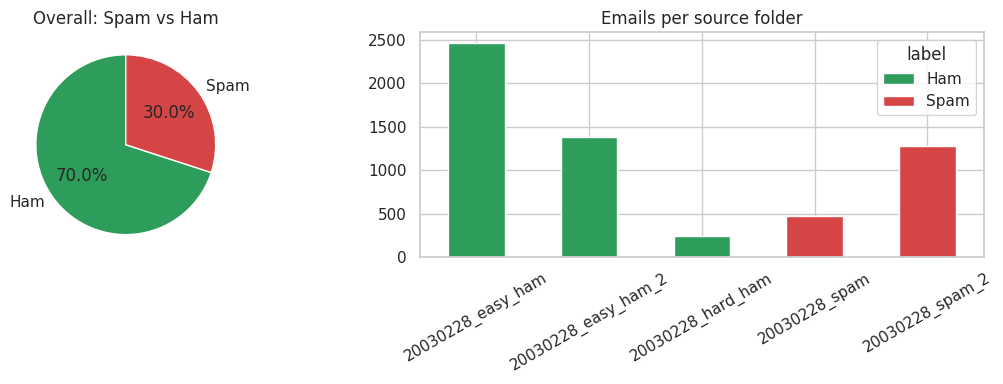

label
Ham     4093
Spam    1755


In [9]:
counts = df["label"].value_counts().reindex(COLORS)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].pie(counts, labels=counts.index, colors=[COLORS[k] for k in counts.index], autopct="%1.1f%%", startangle=90)
ax[0].set_title("Overall: Spam vs Ham")
by_src = pd.crosstab(df["source"], df["label"])[list(COLORS)]
by_src.plot(kind="bar", stacked=True, color=list(COLORS.values()), ax=ax[1])
ax[1].set_title("Emails per source folder"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
print(counts.to_string())

### 5c. Email length — are spam and ham different sizes?

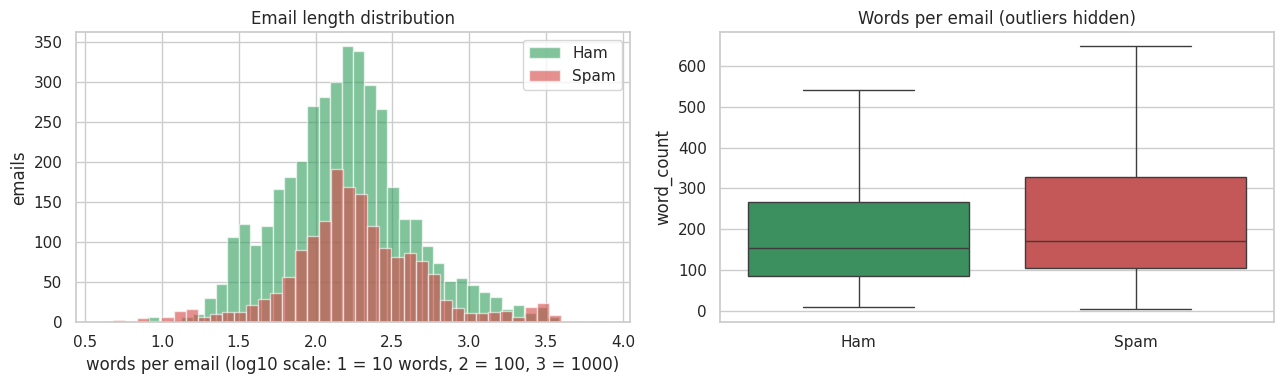

word_count         char_len          url_count       exclam_count        \
          median    mean   median     mean    median  mean       median  mean   
label                                                                           
Ham        153.0  267.58   1018.0  1814.48       1.0  3.79          0.0  0.84   
Spam       170.0  341.82   1241.0  2239.79       2.0  2.38          3.0  5.80   

      caps_ratio        
          median  mean  
label                   
Ham         0.06  0.07  
Spam        0.09  0.12

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for lab, col in COLORS.items():
    ax[0].hist(np.log10(df.loc[df.label == lab, "word_count"].clip(lower=1)), bins=40, alpha=.6, color=col, label=lab)
ax[0].set_xlabel("words per email (log10 scale: 1 = 10 words, 2 = 100, 3 = 1000)"); ax[0].set_ylabel("emails"); ax[0].legend()
ax[0].set_title("Email length distribution")
sns.boxplot(data=df, x="label", y="word_count", order=list(COLORS), hue="label", palette=COLORS, legend=False, ax=ax[1], showfliers=False)
ax[1].set_title("Words per email (outliers hidden)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

display(df.groupby("label")[["word_count", "char_len", "url_count", "exclam_count", "caps_ratio"]].agg(["median", "mean"]).round(2))

### 5d. Other signals: URLs, HTML, exclamation marks
⚠ These are **descriptive**. A URL or HTML alone does **not** prove spam — newsletters from real companies have both.

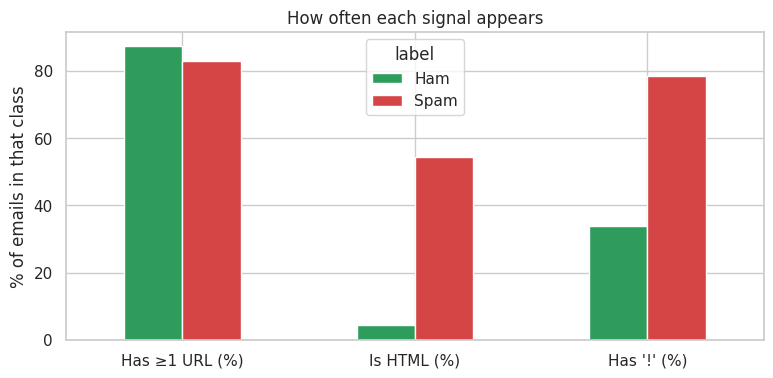

,Has ≥1 URL (%),Is HTML (%),Has '!' (%)
label,,,
Ham,87.2,4.4,33.7
Spam,82.9,54.2,78.4


In [11]:
flags = pd.DataFrame({"label": df["label"], "Has ≥1 URL (%)": df["url_count"] > 0,
                      "Is HTML (%)": df["has_html"], "Has '!' (%)": df["exclam_count"] > 0})
sig = (flags.groupby("label").mean() * 100).reindex(list(COLORS))
ax = sig.T.plot(kind="bar", color=[COLORS[k] for k in sig.index], figsize=(9, 4))
ax.set_ylabel("% of emails in that class"); ax.set_title("How often each signal appears"); plt.xticks(rotation=0); plt.show()
sig.round(1)

### 5e. Most common words in Spam vs Ham
(We remove English stop-words like *the, and, is* and our placeholder tokens. This is only for **description** — the real model's vocabulary is learned later from the training set only.)

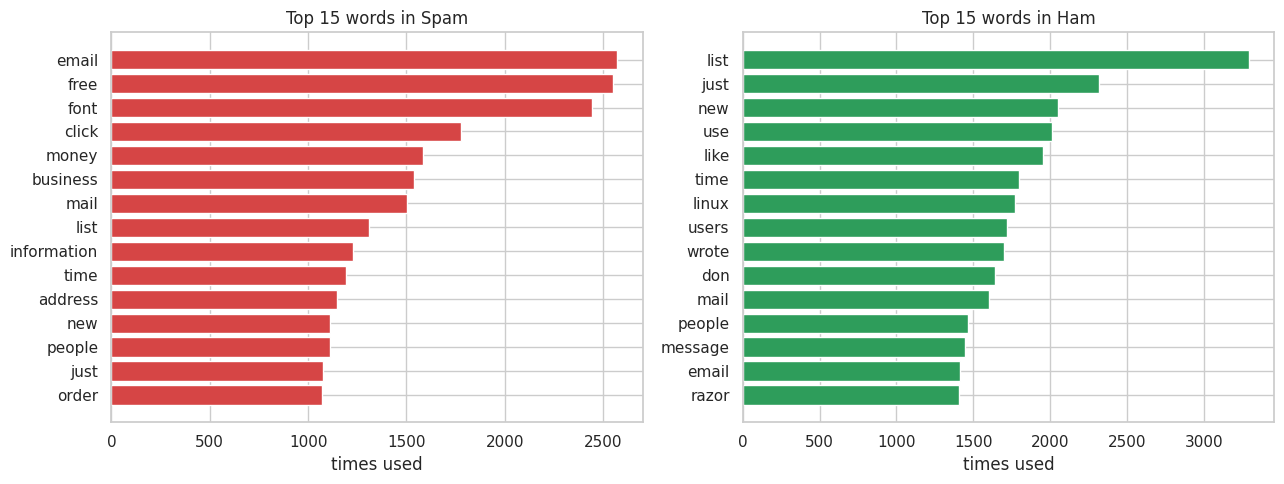

In [12]:
PLACEHOLDERS = {"urltoken", "emailaddr", "moneytoken", "numtoken"}
eda_vec = CountVectorizer(stop_words="english", min_df=5, token_pattern=r"(?u)\b[a-z]{3,}\b")
Xc = eda_vec.fit_transform(df["clean_text"])
vocab = np.array(eda_vec.get_feature_names_out())
keep = np.array([w not in PLACEHOLDERS for w in vocab])

def top_words(label, n=15):
    mask = (df["label"] == label).values
    total = np.asarray(Xc[mask].sum(axis=0)).ravel()
    docs  = np.asarray((Xc[mask] > 0).sum(axis=0)).ravel()
    idx = [i for i in np.argsort(total)[::-1] if keep[i]][:n]
    return pd.DataFrame({"word": vocab[idx], "count": total[idx], "emails_containing": docs[idx]})

top_spam, top_ham = top_words("Spam"), top_words("Ham")
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, tw, lab in zip(ax, (top_spam, top_ham), ("Spam", "Ham")):
    a.barh(tw["word"][::-1], tw["count"][::-1], color=COLORS[lab]); a.set_title(f"Top 15 words in {lab}"); a.set_xlabel("times used")
plt.tight_layout(); plt.show()

💡 Frequent words are not always *distinctive* words (e.g. "list" may be common in both). Step 9 (Explainable AI) finds the words that **separate** spam from ham.

## Step 6 — Split the data and train the machine-learning models
### 🛡 How we avoid data leakage
| Risk | Our protection |
|---|---|
| Same email in train **and** test | Duplicates removed in Step 4 |
| Test emails influence the vocabulary | The **split happens first**; TF-IDF is fitted **inside a Pipeline on training data only** |
| Choosing a model by peeking at the test set | We choose the best model with **cross-validation on the training set**; the test set is used **once** for the final report |
| Learning header artefacts | Headers are never fed to the models (Step 2–3) |

### The two classic models
* **TF-IDF + Logistic Regression** — TF-IDF turns each email into numbers (*how special is each word in this email?*); Logistic Regression learns a weight per word (positive weight → spam, negative → ham).
* **Multinomial Naive Bayes** — a probability model: *"how likely is this word in spam vs in ham?"*, multiplied across all words. Very fast, a classic for spam.

In [17]:
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df["y"], random_state=SEED)
df["split"] = "Train"; df.loc[test_df.index, "split"] = "Test"
X_train, y_train = train_df["clean_text"], train_df["y"]
X_test,  y_test  = test_df["clean_text"],  test_df["y"]
print(f"Training emails: {len(train_df)}   (spam {y_train.mean():.1%})")
print(f"Testing emails : {len(test_df)}   (spam {y_test.mean():.1%})   ← locked away until final evaluation")

Training emails: 4678   (spam 30.0%)
Testing emails : 1170   (spam 30.0%)   ← locked away until final evaluation


In [18]:
def make_pipe(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3, max_df=0.9,
                                  sublinear_tf=True, max_features=50000)),
        ("clf", clf)])

searches = {
    "Logistic Regression":      GridSearchCV(make_pipe(LogisticRegression(max_iter=1000)),
                                             {"clf__C": [1, 10]}, scoring="f1", cv=3, n_jobs=-1),
    "Multinomial Naive Bayes":  GridSearchCV(make_pipe(MultinomialNB()),
                                             {"clf__alpha": [0.1, 0.5, 1.0]}, scoring="f1", cv=3, n_jobs=-1),
}

trained, results = {}, {}
for name, gs in searches.items():
    t0 = time.time()
    gs.fit(X_train, y_train)                     # cross-validation happens on TRAINING data only
    trained[name] = gs.best_estimator_
    results[name] = {"cv_f1_train": gs.best_score_, "best_params": gs.best_params_, "train_seconds": time.time() - t0}
    print(f"✔ {name:25} best settings {gs.best_params_}   cross-val F1 (train only) = {gs.best_score_:.4f}   [{time.time()-t0:.0f}s]")

✔ Logistic Regression       best settings {'clf__C': 10}   cross-val F1 (train only) = 0.9624   [50s]
✔ Multinomial Naive Bayes   best settings {'clf__alpha': 0.1}   cross-val F1 (train only) = 0.9633   [50s]


✅ Both models are trained. **Cross-validation F1** is an honest estimate made *inside the training set* — we use it to pick the "deployed" model in Step 8.

## Step 7 — ⭐ Optional: a compact transformer (DistilBERT)
### Is this a "Small Language Model"?
**DistilBERT** (≈66 million parameters) is a *compact transformer* — a distilled, smaller version of BERT. It reads whole sentences and understands word order and context, unlike TF-IDF which only counts words. It is the kind of compact model people mean when they say "small language model for classification".
(Truly generative SLMs like Qwen-0.5B/SmolLM exist, but they are overkill and slower for a simple Spam/Ham label.)

| | TF-IDF + LR / Naive Bayes | DistilBERT |
|---|---|---|
| Understands word order / context | ❌ | ✅ |
| Training time | seconds | minutes (GPU) / much slower on CPU |
| Memory / download | tiny | ~270 MB download, needs GPU for comfort |
| Explainability | easy (word weights) | hard |
| Needs lots of data | no | benefits from more, but starts pre-trained |

**Limitations here:** we fine-tune on a *small sample* of the training set and read only the first 128 tokens of each email, so it is a demonstration, not a tuned system.

👉 To enable: set `RUN_TRANSFORMER = True` in Step 0, switch Colab to a GPU (**Runtime ▸ Change runtime type ▸ T4 GPU**), re-run Step 0, then run the next cell.
If you leave it `False`, the cell just prints a message and **the rest of the project still works**.

In [19]:
transformer_ready = False
if not RUN_TRANSFORMER:
    print("ℹ DistilBERT skipped (RUN_TRANSFORMER = False). The main project does not need it.")
else:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        device = "cuda" if torch.cuda.is_available() else "cpu"
        n_train, epochs = (2000, 2) if device == "cuda" else (500, 1)
        MAXLEN, BATCH = 128, 16
        print(f"Device: {device}   training on {min(n_train, len(train_df))} emails for {epochs} epoch(s)")
        if device == "cpu":
            print("⚠ No GPU found: this will be slow (several minutes). Consider Runtime ▸ Change runtime type ▸ T4 GPU.")
        torch.manual_seed(SEED)
        tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
        bert = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2).to(device)
        opt = torch.optim.AdamW(bert.parameters(), lr=5e-5)

        def encode(texts):
            enc = tok([t[:2000] for t in texts], truncation=True, padding=True, max_length=MAXLEN, return_tensors="pt")
            return {k: v.to(device) for k, v in enc.items()}

        sub = train_df.sample(n=min(n_train, len(train_df)), random_state=SEED)
        t0 = time.time(); bert.train()
        for ep in range(epochs):
            shuffled = sub.sample(frac=1.0, random_state=SEED + ep)
            for i in range(0, len(shuffled), BATCH):
                chunk = shuffled.iloc[i:i + BATCH]
                out = bert(**encode(chunk["text_plain"].tolist()), labels=torch.tensor(chunk["y"].values).to(device))
                out.loss.backward(); opt.step(); opt.zero_grad()
            print(f"  epoch {ep+1}/{epochs} done  (last batch loss {out.loss.item():.3f})")
        bert.eval(); probs = []
        with torch.no_grad():
            for i in range(0, len(test_df), 32):
                chunk = test_df.iloc[i:i + 32]
                logits = bert(**encode(chunk["text_plain"].tolist())).logits
                probs.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy().tolist())
        bert_proba = np.array(probs)
        results["DistilBERT (optional)"] = {"cv_f1_train": np.nan, "best_params": {"train_emails": len(sub), "epochs": epochs},
                                            "train_seconds": time.time() - t0}
        transformer_ready = True
        print(f"✔ DistilBERT finished in {time.time()-t0:.0f}s")
        del bert, opt
        if device == "cuda": torch.cuda.empty_cache()
    except Exception as e:
        print("✖ DistilBERT could not run — the rest of the project is unaffected.")
        print("  Reason:", type(e).__name__, str(e)[:300])

ℹ DistilBERT skipped (RUN_TRANSFORMER = False). The main project does not need it.


## Step 8 — Evaluate and compare the models (on the untouched test set)
**How to read the metrics** (we treat **Spam as the "positive" class** — the thing we want to catch):

| Metric | Plain-language meaning |
|---|---|
| **Accuracy** | Out of all emails, what share did we label correctly? (can mislead if classes are unbalanced) |
| **Precision** | When we say "Spam", how often are we right? *Low precision = good emails thrown into the spam folder.* |
| **Recall** | Out of all real spam, how much did we catch? *Low recall = spam reaches the inbox.* |
| **F1-score** | One number balancing precision and recall |
| **Confusion matrix** | The 4 outcomes: ✔ true ham, ✔ true spam, ✖ ham sent to spam (**false positive**), ✖ spam let through (**false negative**) |

In [20]:
def evaluate(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"model": name, "accuracy": accuracy_score(y_true, y_pred),
            "precision_spam": precision_score(y_true, y_pred, zero_division=0),
            "recall_spam": recall_score(y_true, y_pred, zero_division=0),
            "f1_spam": f1_score(y_true, y_pred, zero_division=0),
            "TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn)}

test_pred, test_proba = {}, {}
for name, pipe in trained.items():
    test_proba[name] = pipe.predict_proba(X_test)[:, 1]
    test_pred[name]  = (test_proba[name] >= 0.5).astype(int)
if transformer_ready:
    test_proba["DistilBERT (optional)"] = bert_proba
    test_pred["DistilBERT (optional)"]  = (bert_proba >= 0.5).astype(int)

rows = [evaluate(n, y_test, p) for n, p in test_pred.items()]
baseline = np.zeros(len(y_test), dtype=int)                       # "always say Ham"
rows.append(evaluate("Baseline: always Ham", y_test, baseline))
metrics_df = pd.DataFrame(rows)
metrics_df["cv_f1_train"]   = metrics_df["model"].map(lambda m: results.get(m, {}).get("cv_f1_train", np.nan))
metrics_df["train_seconds"] = metrics_df["model"].map(lambda m: results.get(m, {}).get("train_seconds", np.nan))
metrics_df["test_emails"]   = len(y_test)
metrics_df.round(4)

,model,accuracy,precision_spam,recall_spam,f1_spam,TP,TN,FP,FN,cv_f1_train,train_seconds,test_emails
0,Logistic Regression,0.9863,0.9799,0.9744,0.9771,342,812,7,9,0.9624,49.8395,1170
1,Multinomial Naive Bayes,0.9803,0.9713,0.9630,0.9671,338,809,10,13,0.9633,50.2945,1170
2,Baseline: always Ham,0.7000,0.0000,0.0000,0.0000,0,819,0,351,NaN,NaN,1170


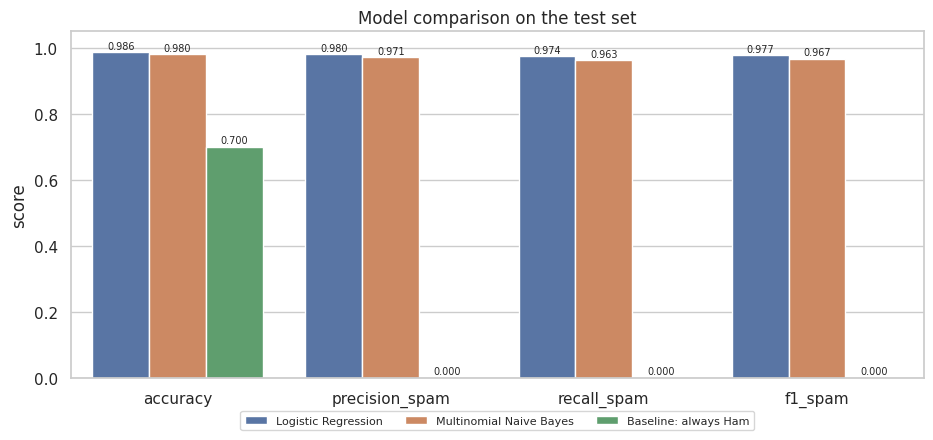

In [21]:
plot_df = metrics_df.melt(id_vars="model", value_vars=["accuracy", "precision_spam", "recall_spam", "f1_spam"],
                          var_name="metric", value_name="score")
plt.figure(figsize=(11, 4.5))
ax = sns.barplot(data=plot_df, x="metric", y="score", hue="model")
ax.set_ylim(0, 1.05); ax.set_title("Model comparison on the test set"); ax.set_xlabel("")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=7, padding=1)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4, fontsize=8); plt.show()

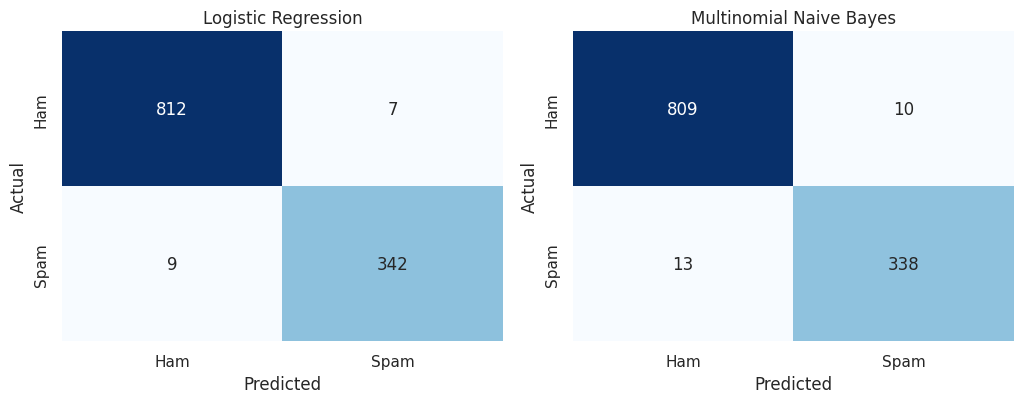

════════════════════════════════════════════════════════════
Logistic Regression
════════════════════════════════════════════════════════════
              precision    recall  f1-score   support

         Ham     0.9890    0.9915    0.9902       819
        Spam     0.9799    0.9744    0.9771       351

    accuracy                         0.9863      1170
   macro avg     0.9845    0.9829    0.9837      1170
weighted avg     0.9863    0.9863    0.9863      1170

════════════════════════════════════════════════════════════
Multinomial Naive Bayes
════════════════════════════════════════════════════════════
              precision    recall  f1-score   support

         Ham     0.9842    0.9878    0.9860       819
        Spam     0.9713    0.9630    0.9671       351

    accuracy                         0.9803      1170
   macro avg     0.9777    0.9754    0.9765      1170
weighted avg     0.9803    0.9803    0.9803      1170



In [22]:
model_names = list(test_pred)
fig, axes = plt.subplots(1, len(model_names), figsize=(5.2 * len(model_names), 4.2))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, model_names):
    cm = confusion_matrix(y_test, test_pred[name], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

for name in model_names:
    print("═" * 60); print(name); print("═" * 60)
    print(classification_report(y_test, test_pred[name], target_names=["Ham", "Spam"], digits=4, zero_division=0))

### Choose the "deployed" model — fairly
We pick the classic model with the best **cross-validation F1 on the training set** (not on the test set), and then read its test results.

In [23]:
classic = {n: results[n]["cv_f1_train"] for n in trained}
deployed_name = max(classic, key=classic.get)
deployed_model = trained[deployed_name]
print(f"🏆 Deployed model: {deployed_name}   (cross-val F1 on training data = {classic[deployed_name]:.4f})")

m = metrics_df[metrics_df.model == deployed_name].iloc[0]
n_spam, n_ham = int((y_test == 1).sum()), int((y_test == 0).sum())
print(f"\nIn plain words, on {len(y_test)} unseen test emails:")
print(f"  • Of {n_spam} real spam emails, {m.TP} were caught and {m.FN} slipped into the inbox.")
print(f"  • Of {n_ham} legitimate emails, {m.TN} were delivered correctly and {m.FP} were wrongly marked as spam.")
print(f"  • When the model says 'Spam', it is right {m.precision_spam:.1%} of the time (precision); it catches {m.recall_spam:.1%} of all spam (recall).")
print(f"  • A lazy 'always Ham' filter would score accuracy {metrics_df[metrics_df.model.str.startswith('Baseline')].accuracy.iloc[0]:.1%} but catch 0 spam.")

🏆 Deployed model: Multinomial Naive Bayes   (cross-val F1 on training data = 0.9633)

In plain words, on 1170 unseen test emails:
  • Of 351 real spam emails, 338 were caught and 13 slipped into the inbox.
  • Of 819 legitimate emails, 809 were delivered correctly and 10 were wrongly marked as spam.
  • When the model says 'Spam', it is right 97.1% of the time (precision); it catches 96.3% of all spam (recall).
  • A lazy 'always Ham' filter would score accuracy 70.0% but catch 0 spam.


### 🔬 Where does the model get it wrong?
Looking at mistakes teaches more than looking at scores. **False positives** (ham → spam) are usually the more costly mistake in practice.

In [24]:
pd.set_option("display.max_colwidth", 110)
tdf = test_df.copy()
tdf["pred"] = test_pred[deployed_name]; tdf["spam_prob"] = test_proba[deployed_name].round(3)
fp_df = tdf[(tdf.y == 0) & (tdf.pred == 1)].sort_values("spam_prob", ascending=False)
fn_df = tdf[(tdf.y == 1) & (tdf.pred == 0)].sort_values("spam_prob")
print(f"❌ Ham wrongly flagged as Spam (false positives): {len(fp_df)}")
display(fp_df[["email_id", "subject", "spam_prob"]].head(5))
print(f"❌ Spam that slipped through (false negatives): {len(fn_df)}")
display(fn_df[["email_id", "subject", "spam_prob"]].head(5))

❌ Ham wrongly flagged as Spam (false positives): 10


,email_id,subject,spam_prob
4091,20030228_hard_ham/00250.c7603b27a45284d12b49adf767b2b6fa,"FC Sporadic for Wednesday, October 30, 2002",1.000
4081,20030228_hard_ham/00240.8623673c2a6f2cde10ab31423f708feb,Espial TV Web Seminar Series - Register Today!,0.995
1548,20030228_easy_ham/01554.0aed12846b3981a2a13adf793083e4f0,[Razor-users] Preproc erasing message,0.995
4075,20030228_hard_ham/00234.12555461ce0bc373baab8daf9280d4ca,Quicker and easier shopping with Tesco.,0.838
3856,20030228_hard_ham/00006.3409dec8ca4fcf2d6e0582554473b5c9,"Virtueller Messetag der jobfair24 am Mittwoch, 03. Juli 2002",0.737


❌ Spam that slipped through (false negatives): 13


,email_id,subject,spam_prob
4609,20030228_spam_2/00046.96a19afe71cd6f1f14c96293557a49ff,Do you Remember Me?,0.003
4610,20030228_spam_2/00047.3c90d41f59137916d6b80e6f8e16ccba,I Can't Wait Anymore!,0.003
5554,20030228_spam_2/01083.a6b3c50be5abf782b585995d2c11176b,HAWAI`I & ENENKIO KINGDOMS AMERICANS SHAME !,0.013
4371,20030228_spam/00290.eb053a191b7509a9399aa16717630414,"Invite: Content Management Summit, Oct. 10th New York City",0.069
5111,20030228_spam_2/00599.d6d6a2edd58fa7dd6b18787e9867984b,Highest Concentration of Pure Human Pheromone OVDKSPCR,0.100


## Step 9 — Explainable AI: *why* did the model decide that?
We must keep two kinds of evidence **separate**:

| | **Model explanation** (this step) | **Heuristic indicator** (Step 10 / DFA) |
|---|---|---|
| Where it comes from | Weights the model **learned from data** | Phrases **we typed in** as rules |
| Does it affect the model's prediction? | ✅ Yes — it *is* the prediction | ❌ No — shown beside it |
| Example | word "remove" has weight +4.2 toward spam | the phrase "click here" matched a rule |

### 9a. Global view — the words the model finds most spam-like / ham-like
For Logistic Regression this is the learned **weight** per word/phrase. For Naive Bayes it is the **log-probability ratio** log P(word|Spam) − log P(word|Ham).

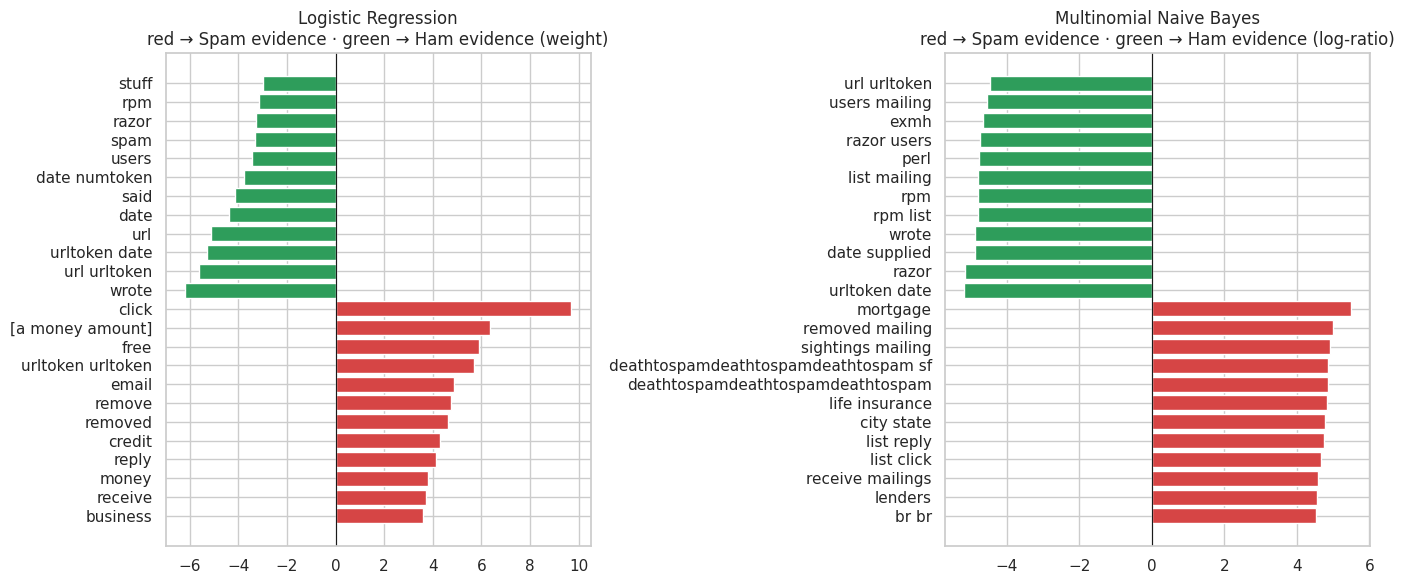

In [25]:
PLACEHOLDER_NAMES = {"urltoken": "[a URL]", "emailaddr": "[an email address]", "moneytoken": "[a money amount]", "numtoken": "[a number]"}
pretty = lambda w: PLACEHOLDER_NAMES.get(w, w)

def feature_weights(pipe):
    vec, clf = pipe.named_steps["tfidf"], pipe.named_steps["clf"]
    names = vec.get_feature_names_out()
    if hasattr(clf, "coef_"):
        w = clf.coef_[0]; kind = "weight"
    else:
        w = clf.feature_log_prob_[1] - clf.feature_log_prob_[0]; kind = "log-ratio"
    return names, w, kind

fig, axes = plt.subplots(1, len(trained), figsize=(7 * len(trained), 6))
axes = np.atleast_1d(axes)
for ax, (name, pipe) in zip(axes, trained.items()):
    names, w, kind = feature_weights(pipe)
    order = np.argsort(w)
    top = list(order[-12:]) + list(order[:12])
    vals = w[top]; labs = [pretty(names[i]) for i in top]
    ax.barh(labs, vals, color=[COLORS["Spam"] if v > 0 else COLORS["Ham"] for v in vals])
    ax.axvline(0, color="k", lw=.8); ax.set_title(f"{name}\nred → Spam evidence · green → Ham evidence ({kind})")
plt.tight_layout(); plt.show()

### 9b. Local view — explain **one** email
For one email, each word's push = (its TF-IDF value in this email) × (its learned weight). Positive → toward Spam, negative → toward Ham.
This is a **true explanation of the model**, not a guess.

In [26]:
def explain_local(pipe, clean_text, k=6):
    vec, clf = pipe.named_steps["tfidf"], pipe.named_steps["clf"]
    x = vec.transform([clean_text])
    idx = x.nonzero()[1]
    if len(idx) == 0:
        return [], []
    names = vec.get_feature_names_out()
    vals = x[0, idx].toarray().ravel()
    w = clf.coef_[0][idx] if hasattr(clf, "coef_") else (clf.feature_log_prob_[1] - clf.feature_log_prob_[0])[idx]
    contrib = vals * w
    order = np.argsort(contrib)
    spam_ev = [(pretty(names[idx[i]]), float(contrib[i])) for i in order[::-1][:k] if contrib[i] > 0]
    ham_ev  = [(pretty(names[idx[i]]), float(contrib[i])) for i in order[:k] if contrib[i] < 0]
    return spam_ev, ham_ev

# explain one real SPAM and one real HAM from the test set (using the deployed model)
for lab in ("Spam", "Ham"):
    row = test_df[test_df.label == lab].iloc[0]
    sp, hm = explain_local(deployed_model, row["clean_text"])
    p = deployed_model.predict_proba([row["clean_text"]])[0, 1]
    print(f"📧 Real {lab} email — subject: {row['subject'][:70]!r}")
    print(f"   Model spam probability: {p:.1%}")
    print("   → pushes toward SPAM :", ", ".join(f"{w} ({c:+.2f})" for w, c in sp) or "—")
    print("   → pushes toward HAM  :", ", ".join(f"{w} ({c:+.2f})" for w, c in hm) or "—", "\n")

📧 Real Spam email — subject: 'MORTGAGE INFORMATION FOR YOU!........'
   Model spam probability: 100.0%
   → pushes toward SPAM : mortgage (+0.99), br br (+0.86), br (+0.85), lenders (+0.39), mortgage rates (+0.38), font (+0.37)
   → pushes toward HAM  : trying (-0.11), shot (-0.08), got (-0.06), problems (-0.04), little (-0.04), telling (-0.04) 

📧 Real Ham email — subject: 'Re: [ILUG] Sparc Solaris (was: Dell GX260 V Redhat 7.3)'
   Model spam probability: 0.0%
   → pushes toward SPAM : prompt (+0.10), major problem (+0.09), numtoken drop (+0.08), hidden (+0.07), time linux (+0.06), easily (+0.04)
   → pushes toward HAM  : boot (-0.53), yeah (-0.45), console (-0.40), prom (-0.40), gnome (-0.40), install (-0.37) 



💡 Some top "spam words" may look odd (e.g. words from mailing-list footers). That is a real finding: **the model learns patterns of this particular corpus**. It may not generalise perfectly to modern email — see the discussion in Step 14.

## Step 10 — Finite Automata: a rule-based pattern detector (the DFA)
### What is a DFA?
A **Deterministic Finite Automaton** is a tiny machine that reads symbols one at a time and moves between a fixed set of **states**. At the end, the state it is in gives the answer.
It has **no learning** and **no probabilities** — only rules we wrote. That is why it is **completely separate from the AI/ML classifier**.

### Our DFA: "which kinds of suspicious indicators have appeared in this email?"
We read the email word by word and convert each word into one **input symbol**:

| Symbol | Meaning | Examples (our rules) |
|:--:|---|---|
| **M** | Money / promotional phrase | free, winner, prize, cash, discount, offer, loan, `$100`, `50%` |
| **A** | Urgency / call-to-action phrase | urgent, act now, click here, limited time, verify your, expires |
| **U** | A URL / web link | `http://…`, `https://…`, `www.…` |
| **N** | Anything else (neutral word) | every other word |

The state remembers **which of M, A, U have been seen so far** (8 possible combinations). We call the email an **ALERT** if **two or more different kinds** of indicator appeared (e.g. a promotional phrase **and** a link).

> ⚠ **A single URL or a single keyword is NOT proof of spam.** Real newsletters have links and the word "offer". That is why one indicator alone ends in a *weak signal*, never an alert.

In [27]:
# ─────────── Rule lists (hand-written heuristics — NOT learned from data) ───────────
M_PHRASES = ["free", "winner", "prize", "cash", "bonus", "discount", "offer", "deal", "cheap", "guaranteed",
             "lottery", "casino", "million", "loan", "mortgage", "refinance", "make money", "earn money",
             "risk free", "no obligation", "credit card", "viagra"]
A_PHRASES = ["urgent", "act now", "act today", "immediately", "limited time", "expires", "click here", "click below",
             "click now", "verify your", "confirm your", "last chance", "hurry", "order now", "call now",
             "apply now", "buy now", "sign up now", "don't miss", "once in a lifetime", "reply now"]

def _alt(phrases):
    return "|".join(re.escape(p) for p in sorted(phrases, key=len, reverse=True))

DFA_TOKEN_RE = re.compile(
    r"(?P<U>(?:https?://|www\.)[^\s<>\"')\]]+)"
    r"|(?P<M>\b(?:" + _alt(M_PHRASES) + r")\b|[$£€]\s?\d[\d,]*(?:\.\d+)?|\d+\s?%)"
    r"|(?P<A>\b(?:" + _alt(A_PHRASES) + r")\b)"
    r"|(?P<W>[a-z][a-z']*)", re.I)

def to_symbols(text):
    # Convert an email into a list of (symbol, original_text). Neutral words become 'N'.
    out = []
    for m in DFA_TOKEN_RE.finditer(text.lower()):
        g = m.lastgroup
        out.append((g if g in ("U", "M", "A") else "N", m.group(0)))
    return out

class EmailDFA:
    # 5-tuple (Q, Σ, δ, q0, F)
    DESC = {"q0": "no indicators", "q1": "{M} promo only", "q2": "{A} urgency only", "q3": "{U} URL only",
            "q4": "{M,A} promo + urgency", "q5": "{M,U} promo + URL", "q6": "{A,U} urgency + URL", "q7": "{M,A,U} all three"}
    SEEN = {"q0": (), "q1": ("M",), "q2": ("A",), "q3": ("U",), "q4": ("M", "A"), "q5": ("M", "U"), "q6": ("A", "U"), "q7": ("M", "A", "U")}
    def __init__(self):
        self.Q = list(self.SEEN)
        self.Sigma = ["M", "A", "U", "N"]
        self.q0 = "q0"
        self.F = [q for q in self.Q if len(self.SEEN[q]) >= 2]            # accepting = ALERT
        by_set = {frozenset(v): k for k, v in self.SEEN.items()}
        self.delta = {}
        for q in self.Q:
            for s in self.Sigma:
                new = frozenset(self.SEEN[q]) | ({s} if s != "N" else set())
                self.delta[(q, s)] = by_set[new]
        assert len(self.delta) == len(self.Q) * len(self.Sigma)             # complete: every (state, symbol) has a move
    def run(self, symbols):
        state, trace = self.q0, []
        for s in symbols:
            nxt = self.delta[(state, s)]
            trace.append((state, s, nxt)); state = nxt
        return state, trace
    def result(self, state):
        n = len(self.SEEN[state])
        return "ALERT: combination of indicators" if n >= 2 else ("Weak signal: single indicator" if n == 1 else "Clean: no indicators")

dfa = EmailDFA()
print("DFA  M = (Q, Σ, δ, q0, F)")
print("  Q  (states)         =", dfa.Q)
print("  Σ  (input symbols)  =", dfa.Sigma)
print("  q0 (initial state)  =", dfa.q0)
print("  F  (accepting)      =", dfa.F, " ← ALERT states (≥ 2 different indicator kinds)")
print("\nState meanings:"); [print(f"  {q}: {dfa.DESC[q]}") for q in dfa.Q]
print("\nTransition function δ  (row = current state, column = input symbol → next state):")
display(pd.DataFrame([[dfa.delta[(q, s)] for s in dfa.Sigma] for q in dfa.Q], index=[f"{q} {'(accepting)' if q in dfa.F else ''}" for q in dfa.Q], columns=dfa.Sigma))

DFA  M = (Q, Σ, δ, q0, F)
  Q  (states)         = ['q0', 'q1', 'q2', 'q3', 'q4', 'q5', 'q6', 'q7']
  Σ  (input symbols)  = ['M', 'A', 'U', 'N']
  q0 (initial state)  = q0
  F  (accepting)      = ['q4', 'q5', 'q6', 'q7']  ← ALERT states (≥ 2 different indicator kinds)

State meanings:
  q0: no indicators
  q1: {M} promo only
  q2: {A} urgency only
  q3: {U} URL only
  q4: {M,A} promo + urgency
  q5: {M,U} promo + URL
  q6: {A,U} urgency + URL
  q7: {M,A,U} all three

Transition function δ  (row = current state, column = input symbol → next state):


,M,A,U,N
q0,q1,q2,q3,q0
q1,q1,q4,q5,q1
q2,q4,q2,q6,q2
q3,q5,q6,q3,q3
q4 (accepting),q4,q4,q7,q4
q5 (accepting),q5,q7,q5,q5
q6 (accepting),q7,q6,q6,q6
q7 (accepting),q7,q7,q7,q7


### State diagram
Each circle is a state; **double circle = accepting (ALERT)**. Arrows show what happens when a symbol arrives. (Not drawn to avoid clutter: **N** loops back to the same state, and repeating a symbol already seen also loops back.)

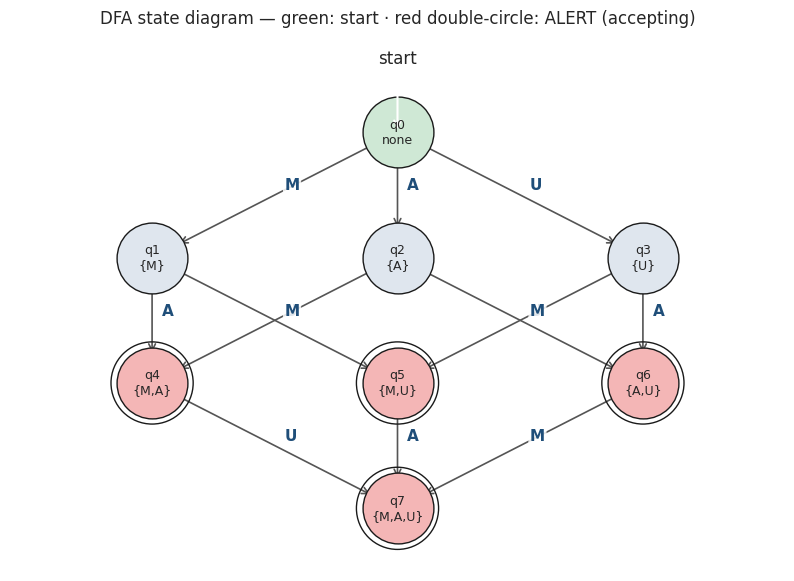

In [28]:
pos = {"q0": (0.5, 0), "q1": (0.12, 1), "q2": (0.5, 1), "q3": (0.88, 1),
       "q4": (0.12, 2), "q5": (0.5, 2), "q6": (0.88, 2), "q7": (0.5, 3)}
fig, ax = plt.subplots(figsize=(10, 7))
for (q, s), nxt in dfa.delta.items():
    if q != nxt:                                              # draw only transitions that change state
        (x1, y1), (x2, y2) = pos[q], pos[nxt]
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="->", color="#555", shrinkA=22, shrinkB=22, lw=1.2))
        ax.text((x1 + x2) / 2 + 0.015, (y1 + y2) / 2 - 0.04, s, fontsize=11, color="#1f4e79", fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=.85))
for q, (x, y) in pos.items():
    col = "#f4b6b6" if q in dfa.F else ("#dfe6ee" if q != "q0" else "#cfe8d5")
    ax.scatter([x], [y], s=2600, color=col, edgecolor="k", zorder=3)
    if q in dfa.F: ax.scatter([x], [y], s=3500, facecolors="none", edgecolors="k", zorder=3)   # double circle
    ax.text(x, y, f"{q}\n{'none' if q == 'q0' else dfa.DESC[q].split(' ')[0]}", ha="center", va="center", fontsize=9, zorder=4)
ax.annotate("start", xy=pos["q0"], xytext=(0.5, -0.55), ha="center", arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_xlim(-0.1, 1.1); ax.set_ylim(3.5, -0.8); ax.axis("off")
ax.set_title("DFA state diagram — green: start · red double-circle: ALERT (accepting)")
plt.show()

### Watch the DFA work — state transitions for example emails
Each row is one input word → symbol → state change. (We use **original, made-up** emails, not real people's mail.)

In [29]:
EXAMPLES = {
    "1. Promo scam":        "URGENT: You are a winner! Click here http://claim-prize.example/win to get your $1,000 cash bonus now.",
    "2. Normal link":       "Hi team, the meeting notes are on https://wiki.example.com/notes. Please review before Friday.",
    "3. Keyword only":      "I will send you the discount invoice for the free trial tomorrow morning.",
    "4. Newsletter":        "Weekly newsletter: 20% off our book club this week. Details at www.bookclub.example",
    "5. Plain ham":         "Lunch at noon on Thursday? Let me know if the new place near the office works for you.",
}

def show_trace(text, max_rows=60):
    syms = to_symbols(text)
    state, trace = dfa.run([s for s, _ in syms])
    rows = [{"step": i + 1, "word/phrase": w[:28], "symbol": s, "transition": f"{a} --{s}--> {b}"}
            for i, ((s, w), (a, _, b)) in enumerate(zip(syms, trace))]
    display(pd.DataFrame(rows).head(max_rows))
    return state

for title, text in EXAMPLES.items():
    print(f"\n━━ Example {title}\n   “{text}”")
    final = show_trace(text)
    print(f"   ➜ Final state: {final} ({dfa.DESC[final]})   Accepting: {final in dfa.F}   Result: {dfa.result(final)}")


━━ Example 1. Promo scam
   “URGENT: You are a winner! Click here http://claim-prize.example/win to get your $1,000 cash bonus now.”


,step,word/phrase,symbol,transition
0,1,urgent,A,q0 --A--> q2
1,2,you,N,q2 --N--> q2
2,3,are,N,q2 --N--> q2
3,4,a,N,q2 --N--> q2
4,5,winner,M,q2 --M--> q4
5,6,click here,A,q4 --A--> q4
6,7,http://claim-prize.example/w,U,q4 --U--> q7
7,8,to,N,q7 --N--> q7
8,9,get,N,q7 --N--> q7
9,10,your,N,q7 --N--> q7


   ➜ Final state: q7 ({M,A,U} all three)   Accepting: True   Result: ALERT: combination of indicators

━━ Example 2. Normal link
   “Hi team, the meeting notes are on https://wiki.example.com/notes. Please review before Friday.”


,step,word/phrase,symbol,transition
0,1,hi,N,q0 --N--> q0
1,2,team,N,q0 --N--> q0
2,3,the,N,q0 --N--> q0
3,4,meeting,N,q0 --N--> q0
4,5,notes,N,q0 --N--> q0
5,6,are,N,q0 --N--> q0
6,7,on,N,q0 --N--> q0
7,8,https://wiki.example.com/not,U,q0 --U--> q3
8,9,please,N,q3 --N--> q3
9,10,review,N,q3 --N--> q3


   ➜ Final state: q3 ({U} URL only)   Accepting: False   Result: Weak signal: single indicator

━━ Example 3. Keyword only
   “I will send you the discount invoice for the free trial tomorrow morning.”


...

   ➜ Final state: q1 ({M} promo only)   Accepting: False   Result: Weak signal: single indicator

━━ Example 4. Newsletter
   “Weekly newsletter: 20% off our book club this week. Details at www.bookclub.example”


,step,word/phrase,symbol,transition
0,1,weekly,N,q0 --N--> q0
1,2,newsletter,N,q0 --N--> q0
2,3,20%,M,q0 --M--> q1
3,4,off,N,q1 --N--> q1
4,5,our,N,q1 --N--> q1
5,6,book,N,q1 --N--> q1
6,7,club,N,q1 --N--> q1
7,8,this,N,q1 --N--> q1
8,9,week,N,q1 --N--> q1
9,10,details,N,q1 --N--> q1


   ➜ Final state: q5 ({M,U} promo + URL)   Accepting: True   Result: ALERT: combination of indicators

━━ Example 5. Plain ham
   “Lunch at noon on Thursday? Let me know if the new place near the office works for you.”


,step,word/phrase,symbol,transition
0,1,lunch,N,q0 --N--> q0
1,2,at,N,q0 --N--> q0
2,3,noon,N,q0 --N--> q0
3,4,on,N,q0 --N--> q0
4,5,thursday,N,q0 --N--> q0
5,6,let,N,q0 --N--> q0
6,7,me,N,q0 --N--> q0
7,8,know,N,q0 --N--> q0
8,9,if,N,q0 --N--> q0
9,10,the,N,q0 --N--> q0


   ➜ Final state: q0 (no indicators)   Accepting: False   Result: Clean: no indicators


👀 Compare examples **2, 3, 4**: a link alone (2) or a keyword alone (3) ends in a **weak signal**, not an alert. Example 4 is a *legitimate-looking newsletter* that still triggers the rule combination — a reminder that **rules can raise false alarms**.
Now we run the DFA on **every** email in the dataset.

✔ DFA processed 5848 emails in 5s


dfa_result,Clean: no indicators,Weak signal: single indicator,ALERT: combination of indicators
label,,,
Ham,378,2649,1066
Spam,34,339,1382


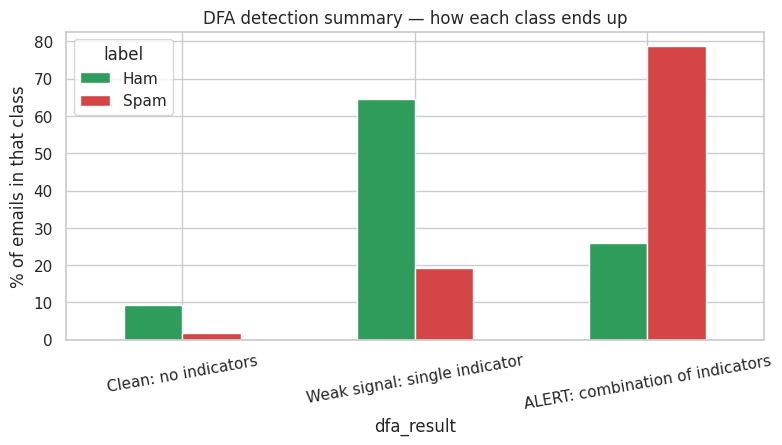

In [30]:
def dfa_analyze(text):
    syms = to_symbols(text)
    state, trace = dfa.run([s for s, _ in syms])
    hits = [(s, w) for s, w in syms if s != "N"]
    changes = [f"{a}-{s}->{b}" for a, s, b in trace if a != b]
    return {"dfa_final_state": state, "dfa_state_meaning": dfa.DESC[state], "dfa_result": dfa.result(state),
            "dfa_alert": "Yes" if state in dfa.F else "No",
            "money_hits": sum(1 for s, _ in hits if s == "M"), "action_hits": sum(1 for s, _ in hits if s == "A"),
            "url_hits": sum(1 for s, _ in hits if s == "U"), "dfa_categories_seen": len(dfa.SEEN[state]),
            "dfa_trace": " | ".join(changes) if changes else "q0 (no state change)",
            "dfa_matches": "; ".join(dict.fromkeys(w[:30] for _, w in hits))[:200]}

t0 = time.time()
dfa_df = pd.DataFrame([dfa_analyze(t) for t in df["text_plain"]], index=df.index)
for c in dfa_df.columns: df[c] = dfa_df[c]
print(f"✔ DFA processed {len(df)} emails in {time.time()-t0:.0f}s")

order = ["Clean: no indicators", "Weak signal: single indicator", "ALERT: combination of indicators"]
tab = pd.crosstab(df["label"], df["dfa_result"]).reindex(columns=order, fill_value=0)
display(tab)
pct = (tab.div(tab.sum(axis=1), axis=0) * 100).round(1)
ax = pct.reindex(list(COLORS)).T.plot(kind="bar", color=[COLORS[k] for k in pct.reindex(list(COLORS)).index], figsize=(9, 4))
ax.set_ylabel("% of emails in that class"); ax.set_title("DFA detection summary — how each class ends up"); plt.xticks(rotation=10); plt.show()

### Treat the DFA as a (weak) classifier, just to compare
If we *pretended* "ALERT = spam", how would it score on the same test emails? This shows why a hand-written rule is **not** a replacement for a trained model.

In [31]:
dfa_test_pred = (df.loc[test_df.index, "dfa_alert"] == "Yes").astype(int).values
dfa_row = evaluate("DFA rules (ALERT = spam)", y_test, dfa_test_pred)
dfa_row.update({"cv_f1_train": np.nan, "train_seconds": 0.0, "test_emails": len(y_test)})

metrics_df = metrics_df[~metrics_df.model.str.startswith("DFA")]
metrics_df = pd.concat([metrics_df, pd.DataFrame([dfa_row])], ignore_index=True)
metrics_df["model_type"] = metrics_df["model"].map(
    lambda m: "Rule-based (DFA)" if m.startswith("DFA") else ("Baseline" if m.startswith("Baseline") else "Machine learning"))
metrics_df["is_deployed"] = np.where(metrics_df["model"] == deployed_name, "Yes", "No")
metrics_df.round(4)

,model,accuracy,precision_spam,recall_spam,f1_spam,TP,TN,FP,FN,cv_f1_train,train_seconds,test_emails,model_type,is_deployed
0,Logistic Regression,0.9863,0.9799,0.9744,0.9771,342,812,7,9,0.9624,49.8395,1170,Machine learning,No
1,Multinomial Naive Bayes,0.9803,0.9713,0.9630,0.9671,338,809,10,13,0.9633,50.2945,1170,Machine learning,Yes
2,Baseline: always Ham,0.7000,0.0000,0.0000,0.0000,0,819,0,351,NaN,NaN,1170,Baseline,No
3,DFA rules (ALERT = spam),0.7376,0.5455,0.7521,0.6323,264,599,220,87,NaN,0.0000,1170,Rule-based (DFA),No


## Step 11 — Combine the AI model and the DFA (without over-trusting either)
| ML model says | DFA says | Combined verdict | Meaning |
|---|---|---|---|
| Spam | ALERT | 🔴 **High risk** | two independent methods agree |
| Spam | no alert | 🟠 **Spam (model only)** | the model saw patterns our simple rules do not cover |
| Ham | ALERT | 🟡 **Review** | rules fired but the model disagrees — could be a newsletter |
| Ham | no alert | 🟢 **Looks legitimate** | |

The **ML model is the decision-maker**; the DFA is an extra, human-readable **signal**.

In [32]:
# predictions for ALL emails with every trained model (rows with split == "Train" were seen in training → don't use them for performance claims)
for name, pipe in trained.items():
    key = "LR" if "Logistic" in name else "NB"
    df[f"prob_{key}"] = pipe.predict_proba(df["clean_text"])[:, 1].round(4)
    df[f"pred_{key}"] = np.where(df[f"prob_{key}"] >= 0.5, "Spam", "Ham")
dep_key = "LR" if "Logistic" in deployed_name else "NB"
df["deployed_model"] = deployed_name
df["spam_prob"]      = df[f"prob_{dep_key}"]
df["pred_label"]     = df[f"pred_{dep_key}"]
df["outcome"] = np.select([(df.label == "Spam") & (df.pred_label == "Spam"), (df.label == "Ham") & (df.pred_label == "Ham"),
                           (df.label == "Ham") & (df.pred_label == "Spam")], ["TP", "TN", "FP"], default="FN")
df["correct"] = np.where(df.label == df.pred_label, "Correct", "Wrong")

def combine(pred, alert):
    if pred == "Spam": return "High risk (ML + DFA agree)" if alert == "Yes" else "Spam (ML only)"
    return "Review (DFA alert, ML says Ham)" if alert == "Yes" else "Looks legitimate"
df["combined_verdict"] = [combine(p, a) for p, a in zip(df["pred_label"], df["dfa_alert"])]

if transformer_ready:
    df["pred_DistilBERT"] = np.nan; df["prob_DistilBERT"] = np.nan
    df["pred_DistilBERT"] = df["pred_DistilBERT"].astype(object)
    df.loc[test_df.index, "prob_DistilBERT"] = np.round(bert_proba, 4)
    df.loc[test_df.index, "pred_DistilBERT"] = np.where(bert_proba >= 0.5, "Spam", "Ham")

t = df[df.split == "Test"]
display(pd.crosstab(t["combined_verdict"], t["label"]).reindex(
    ["High risk (ML + DFA agree)", "Spam (ML only)", "Review (DFA alert, ML says Ham)", "Looks legitimate"], fill_value=0))
print("(Test-set emails only.  Columns = TRUE label.)")

label,Ham,Spam
combined_verdict,,
High risk (ML + DFA agree),4,257
Spam (ML only),6,81
"Review (DFA alert, ML says Ham)",216,7
Looks legitimate,593,6


(Test-set emails only.  Columns = TRUE label.)


## Step 12 — ⚡ Automatic classification: type any email, get a verdict
Everything in one function: **parse → clean → model prediction → explanation → DFA → combined verdict → simple explanation**.
It runs entirely inside Colab: no API key, no access to your mailbox.

**Score note:** Logistic Regression probabilities are fairly sensible; **Naive Bayes** probabilities are usually *over-confident* (often near 0% or 100%) — treat them as a ranking score, not an exact chance.

In [33]:
THRESHOLD   = 0.50           # ≥ this → Spam
REVIEW_BAND = (0.35, 0.65)   # probabilities in this range → "needs human review"

def classify_email(raw_text, model=None):
    model = model or deployed_model
    rec   = extract_email(raw_text.encode("utf-8", errors="replace"))
    plain = build_plain(rec)
    clean = clean_for_model(plain)
    if len(clean.split()) < 3:
        return None
    proba = float(model.predict_proba([clean])[0, 1])
    label = "Spam" if proba >= THRESHOLD else "Ham"
    spam_ev, ham_ev = explain_local(model, clean)
    d = dfa_analyze(plain)
    verdict = combine(label, d["dfa_alert"])
    route = "⚠ Needs review" if REVIEW_BAND[0] <= proba <= REVIEW_BAND[1] else ("🗑 Spam folder" if label == "Spam" else "📥 Inbox")
    # ── plain-language explanation ──
    lines = [f"The {deployed_name} model gives this email a {proba:.0%} spam probability, so it is classified as {label.upper()}."]
    if spam_ev: lines.append("Model evidence for SPAM: " + ", ".join(w for w, _ in spam_ev) + ".")
    if ham_ev:  lines.append("Model evidence for HAM: " + ", ".join(w for w, _ in ham_ev) + ".")
    lines.append(f"Separately, the rule-based DFA ended in {d['dfa_final_state']} ({d['dfa_state_meaning']}) → {d['dfa_result']}."
                 + (f" Rules matched: {d['dfa_matches']}." if d["dfa_matches"] else "")
                 + " These are fixed heuristics, not model evidence; one indicator alone is not proof of spam.")
    return {"label": label, "proba": proba, "route": route, "verdict": verdict, "spam_ev": spam_ev, "ham_ev": ham_ev,
            "dfa": d, "explanation": " ".join(lines), "subject": rec["subject"]}

r = classify_email(EXAMPLES["1. Promo scam"])
print(r["label"], f"{r['proba']:.1%}", r["route"], "|", r["verdict"]); print(r["explanation"])

Spam 99.2% 🗑 Spam folder | High risk (ML + DFA agree)
The Multinomial Naive Bayes model gives this email a 99% spam probability, so it is classified as SPAM. Model evidence for SPAM: moneytoken cash, urltoken moneytoken, click urltoken, bonus, cash, urgent. Model evidence for HAM: [a URL]. Separately, the rule-based DFA ended in q7 ({M,A,U} all three) → ALERT: combination of indicators. Rules matched: urgent; winner; click here; http://claim-prize.example/win; $1,000; cash; bonus. These are fixed heuristics, not model evidence; one indicator alone is not proof of spam.


Now the interactive box 👇 Paste a **full email with headers** or just type the **subject and body**. Click **Classify**.
(Tip: start with `Subject: your subject here` on the first line to include a subject.)

In [34]:
import ipywidgets as widgets
from IPython.display import display, HTML

box = widgets.Textarea(placeholder="Subject: ...\n\nType or paste an email here…", layout=widgets.Layout(width="90%", height="130px"))
btn = widgets.Button(description="Classify", button_style="success", icon="search")
out = widgets.Output()

def card(res):
    spam = res["label"] == "Spam"
    color, emoji = ("#d64545", "🚨") if spam else ("#2e9d5b", "✅")
    esc = html.escape
    sp = ", ".join(f"<b>{esc(w)}</b>" for w, _ in res["spam_ev"]) or "—"
    hm = ", ".join(f"<b>{esc(w)}</b>" for w, _ in res["ham_ev"]) or "—"
    d = res["dfa"]
    return HTML(f'''<div style="border-left:8px solid {color};padding:10px 16px;margin-top:6px;background:#f7f9fa;color:#222;border-radius:6px;line-height:1.5">
      <div style="font-size:22px"><b>{emoji} {res["label"].upper()}</b> &nbsp; <span style="font-size:15px">spam probability {res["proba"]:.1%} · {esc(res["route"])}</span></div>
      <div><b>Model evidence</b> (learned) → toward Spam: {sp} &nbsp;|&nbsp; toward Ham: {hm}</div>
      <div><b>DFA (rule-based)</b> → state <b>{d["dfa_final_state"]}</b> ({esc(d["dfa_state_meaning"])}) · {esc(d["dfa_result"])} · matched: {esc(d["dfa_matches"]) or "none"}</div>
      <div><b>Combined verdict:</b> {esc(res["verdict"])}</div>
      <div style="margin-top:6px;font-size:13px;color:#444">{esc(res["explanation"])}</div></div>''')

def on_click(_):
    with out:
        out.clear_output()
        if not box.value.strip():
            print("Please type or paste an email first."); return
        res = classify_email(box.value)
        if res is None:
            print("That text is too short to classify (need at least 3 words)."); return
        display(card(res))

btn.on_click(on_click)
display(box, btn, out)

Textarea(value='', layout=Layout(height='130px', width='90%'), placeholder='Subject: ...\n\nType or paste an e…

Button(button_style='success', description='Classify', icon='search', style=ButtonStyle())

Output()

## Step 12b — ⚡ Live inbox feed (simulation)
Pretend new emails are arriving. Each one is **automatically routed**: 📥 Inbox, 🗑 Spam folder, or ⚠ Needs review. (These are made-up emails.)

In [35]:
incoming = [
    "Subject: Team lunch on Friday\n\nHi all, we are booking the usual place at 12:30 on Friday. Reply if you have dietary requirements.",
    "Subject: YOU HAVE WON!!!\n\nCongratulations winner! Claim your FREE $5,000 cash prize now. Click here: http://prize-claim.example/now Act now, limited time!",
    "Subject: Project report attached\n\nPlease find the quarterly report attached. Let me know if you need any changes before the review meeting.",
    "Subject: Cheap loan approved\n\nGet a guaranteed mortgage refinance with no obligation. Apply now at www.best-loans.example and save thousands.",
    "Subject: Your monthly newsletter\n\nThis month: 15% off all courses and new tutorials. Read more at https://learn.example.org/news",
    "Subject: Exam timetable\n\nThe final examination timetable is published on the department notice board. Please check your slots.",
]
tally = {"📥 Inbox": 0, "🗑 Spam folder": 0, "⚠ Needs review": 0}
for i, em in enumerate(incoming, 1):
    res = classify_email(em)
    tally[res["route"]] += 1
    subj = em.split("\n")[0].replace("Subject: ", "")
    print(f"[{i}] {res['route']:16} {res['label']:5} {res['proba']:6.1%} | DFA {res['dfa']['dfa_final_state']} {res['dfa']['dfa_alert']:3} | {res['verdict']:34} | {subj}")
    print(f"     Live count → 📥 {tally['📥 Inbox']}   🗑 {tally['🗑 Spam folder']}   ⚠ {tally['⚠ Needs review']}\n")
    time.sleep(1.0)

[1] 📥 Inbox          Ham    10.8% | DFA q0 No  | Looks legitimate                   | Team lunch on Friday
     Live count → 📥 1   🗑 0   ⚠ 0

[2] 🗑 Spam folder    Spam   99.3% | DFA q7 Yes | High risk (ML + DFA agree)         | YOU HAVE WON!!!
     Live count → 📥 1   🗑 1   ⚠ 0

[3] 📥 Inbox          Ham     9.5% | DFA q0 No  | Looks legitimate                   | Project report attached
     Live count → 📥 2   🗑 1   ⚠ 0

[4] 🗑 Spam folder    Spam  100.0% | DFA q7 Yes | High risk (ML + DFA agree)         | Cheap loan approved
     Live count → 📥 2   🗑 2   ⚠ 0

[5] 🗑 Spam folder    Spam   66.9% | DFA q5 Yes | High risk (ML + DFA agree)         | Your monthly newsletter
     Live count → 📥 2   🗑 3   ⚠ 0

[6] 📥 Inbox          Ham    18.4% | DFA q0 No  | Looks legitimate                   | Exam timetable
     Live count → 📥 3   🗑 3   ⚠ 0



## Step 13 — Save results for Tableau
We create **4 CSV files** (one row per email, or per model/word):

| File | One row per… | Main use in Tableau |
|---|---|---|
| `email_spam_classification_results.csv` | email | spam/ham counts, spam %, outcomes, filters |
| `email_model_metrics.csv` | model | model performance charts |
| `email_word_frequency.csv` | word × class | word-frequency bars |
| `email_dfa_results.csv` | email | DFA alert charts |

⚠ Rows with `split = Train` were used to train the model. For **performance** views in Tableau, always filter `split = Test`.

In [36]:
# ---------- 1. email_spam_classification_results.csv ----------
exp = df.copy()
exp["subject_short"] = exp["subject"].str.replace(r"\s+", " ", regex=True).str.strip().str[:100]
exp["email_month"]   = exp["email_date"].dt.to_period("M").dt.to_timestamp().dt.strftime("%Y-%m-%d")
exp["email_year"]    = exp["email_date"].dt.year.astype("Int64")
exp["has_html"]      = np.where(exp["has_html"], "Yes", "No")
exp["has_url"]       = np.where(exp["url_count"] > 0, "Yes", "No")
exp["length_bucket"] = pd.cut(exp["word_count"], [-1, 50, 150, 400, 1000, 10**9],
                              labels=["≤50", "51–150", "151–400", "401–1000", ">1000"]).astype(str)
res_cols = ["email_id", "source", "split", "label", "pred_label", "spam_prob", "outcome", "correct", "deployed_model",
            "combined_verdict", "dfa_result", "dfa_alert", "subject_short", "word_count", "char_len", "url_count", "has_url",
            "has_html", "exclam_count", "caps_ratio", "length_bucket", "email_date", "email_month", "email_year",
            "pred_LR", "prob_LR", "pred_NB", "prob_NB"]
if transformer_ready: res_cols += ["pred_DistilBERT", "prob_DistilBERT"]
exp = exp.rename(columns={"label": "label"})[res_cols]
exp.to_csv("email_spam_classification_results.csv", index=False, encoding="utf-8")

# ---------- 2. email_model_metrics.csv ----------
metrics_df.round(4).to_csv("email_model_metrics.csv", index=False, encoding="utf-8")

# ---------- 3. email_word_frequency.csv ----------
rows = []
union = set(top_words("Spam", 40)["word"]) | set(top_words("Ham", 40)["word"])
for lab in ("Spam", "Ham"):
    mask = (df["label"] == lab).values
    total = np.asarray(Xc[mask].sum(axis=0)).ravel(); docs = np.asarray((Xc[mask] > 0).sum(axis=0)).ravel()
    ranks = {vocab[i]: r + 1 for r, i in enumerate([j for j in np.argsort(total)[::-1] if keep[j]])}
    for i, w in enumerate(vocab):
        if w in union:
            rows.append({"word": w, "label": lab, "count": int(total[i]), "emails_containing": int(docs[i]),
                         "pct_of_class_emails": round(100 * docs[i] / mask.sum(), 2), "rank_in_class": ranks[w]})
pd.DataFrame(rows).sort_values(["label", "rank_in_class"]).to_csv("email_word_frequency.csv", index=False, encoding="utf-8")

# ---------- 4. email_dfa_results.csv ----------
dfa_cols = ["email_id", "source", "split", "label", "dfa_final_state", "dfa_state_meaning", "dfa_result", "dfa_alert",
            "money_hits", "action_hits", "url_hits", "dfa_categories_seen", "dfa_trace", "dfa_matches", "pred_label", "combined_verdict"]
df[dfa_cols].to_csv("email_dfa_results.csv", index=False, encoding="utf-8")

for f in ["email_spam_classification_results.csv", "email_model_metrics.csv", "email_word_frequency.csv", "email_dfa_results.csv"]:
    chk = pd.read_csv(f)
    print(f"✔ {f:40} {chk.shape[0]:>6} rows × {chk.shape[1]:>2} columns   ({os.path.getsize(f)/1024:.0f} KB)")

✔ email_spam_classification_results.csv      5848 rows × 28 columns   (1801 KB)
✔ email_model_metrics.csv                       4 rows × 14 columns   (0 KB)
✔ email_word_frequency.csv                    126 rows ×  6 columns   (3 KB)
✔ email_dfa_results.csv                      5848 rows × 16 columns   (1451 KB)


### Check the files, then download

In [37]:
# Sanity checks on what we just saved (each line should say OK)
r = pd.read_csv("email_spam_classification_results.csv"); m = pd.read_csv("email_model_metrics.csv")
w = pd.read_csv("email_word_frequency.csv");              d = pd.read_csv("email_dfa_results.csv")
checks = {
    "results: labels are only Ham/Spam":        set(r["label"]) <= {"Ham", "Spam"},
    "results: no duplicate email_id":           r["email_id"].is_unique,
    "results: spam_prob between 0 and 1":       r["spam_prob"].between(0, 1).all(),
    "results: Train + Test = all rows":         set(r["split"]) == {"Train", "Test"},
    "metrics: has a row for each model":        len(m) >= 4,
    "metrics: scores between 0 and 1":          m[["accuracy", "precision_spam", "recall_spam", "f1_spam"]].stack().between(0, 1).all(),
    "words: both classes present":              set(w["label"]) == {"Ham", "Spam"},
    "dfa: same emails as results":              set(d["email_id"]) == set(r["email_id"]),
    "dfa: alert is Yes/No":                     set(d["dfa_alert"]) <= {"Yes", "No"},
}
for k, v in checks.items(): print("OK  " if v else "FAIL", k)

OK   results: labels are only Ham/Spam
OK   results: no duplicate email_id
OK   results: spam_prob between 0 and 1
OK   results: Train + Test = all rows
OK   metrics: has a row for each model
OK   metrics: scores between 0 and 1
OK   words: both classes present
OK   dfa: same emails as results
OK   dfa: alert is Yes/No


In [42]:
FILES = ["email_spam_classification_results.csv", "email_model_metrics.csv", "email_word_frequency.csv", "email_dfa_results.csv"]
with zipfile.ZipFile("tableau_exports.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in FILES: z.write(f)
print("✔ Created tableau_exports.zip containing:", ", ".join(FILES))
try:
    from google.colab import files
    files.download("tableau_exports.zip")      # your browser will download the zip; unzip it on your computer
except ImportError:
    print("(Not in Colab — the files are in the current folder.)")

✔ Created tableau_exports.zip containing: email_spam_classification_results.csv, email_model_metrics.csv, email_word_frequency.csv, email_dfa_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

💾 **Other ways to get the files:** click the 📁 folder icon on the left of Colab → right-click a file → **Download**.
Colab deletes these files when the runtime is recycled, so download them **now**.

## Step 14 — Results and discussion (generated from *your* run)
The next cell writes the results section using the **actual numbers** from this run and saves it as `Project_Report_Results.md`
(paste it into your project report). Nothing here is typed in advance.

In [41]:
def md_table(frame):
    cols = list(frame.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for _, r_ in frame.iterrows():
        lines.append("| " + " | ".join(f"{v:.4f}" if isinstance(v, (float, np.floating)) and not pd.isna(v) else ("" if (isinstance(v, float) and pd.isna(v)) else str(v)) for v in r_) + " |")
    return "\n".join(lines)

mm = metrics_df[metrics_df.model == deployed_name].iloc[0]
dfa_t = df[df.split == "Test"]
alert_spam = (dfa_t[dfa_t.label == "Spam"].dfa_alert == "Yes").mean() * 100
alert_ham  = (dfa_t[dfa_t.label == "Ham"].dfa_alert == "Yes").mean() * 100
report = f'''# Results and Discussion (auto-generated {datetime.now():%Y-%m-%d %H:%M})

## Dataset
After parsing and cleaning, **{len(df)} emails** remained ({(df.label=="Ham").sum()} Ham, {(df.label=="Spam").sum()} Spam; spam share {100*(df.label=="Spam").mean():.1f}%).
Split: {len(train_df)} training / {len(test_df)} test emails (stratified, random seed {SEED}). Duplicates and conflicting labels were removed before splitting.
Data source: {DATA_SOURCE}. Median email length: {int(df.word_count.median())} words.

## Model comparison (test set, Spam = positive class)
{md_table(metrics_df[["model", "model_type", "accuracy", "precision_spam", "recall_spam", "f1_spam", "TP", "TN", "FP", "FN"]])}

## Deployed model
**{deployed_name}** was selected using cross-validation F1 on the training set only (CV F1 = {classic[deployed_name]:.4f}).
On the test set it caught {int(mm.TP)} of {int(mm.TP + mm.FN)} spam emails and wrongly flagged {int(mm.FP)} of {int(mm.TN + mm.FP)} legitimate emails.

## DFA (rule-based) findings, test set
The DFA raised an ALERT on {alert_spam:.1f}% of spam emails and on {alert_ham:.1f}% of ham emails.
Because the rules are hand-written, they are used as a supporting signal, not as the decision-maker.

## Limitations
* The corpus is a fixed snapshot; language and spam tactics change, so performance on current email may be lower.
* Models were trained on message text only; attachments, images and sender reputation were not used.
* Naive Bayes probabilities tend to be over-confident; use them for ranking rather than as exact chances.
* The DFA word lists are a small hand-written sample and will miss many tactics (and flag some legitimate newsletters).
* Results come from a single random split; a different seed would change the numbers slightly.
'''
if transformer_ready: report += "* DistilBERT was fine-tuned on a small sample with 128-token inputs: a demonstration, not a tuned system.\n"
with open("Project_Report_Results.md", "w", encoding="utf-8") as f: f.write(report)
print(report)

# Results and Discussion (auto-generated 2026-10-27 06:02)

## Dataset
After parsing and cleaning, **5848 emails** remained (4093 Ham, 1755 Spam; spam share 30.0%).
Split: 4678 training / 1170 test emails (stratified, random seed 42). Duplicates and conflicting labels were removed before splitting.
Data source: spamassassin. Median email length: 158 words.

## Model comparison (test set, Spam = positive class)
| model | model_type | accuracy | precision_spam | recall_spam | f1_spam | TP | TN | FP | FN |
|---|---|---|---|---|---|---|---|---|---|
| Logistic Regression | Machine learning | 0.9863 | 0.9799 | 0.9744 | 0.9771 | 342 | 812 | 7 | 9 |
| Multinomial Naive Bayes | Machine learning | 0.9803 | 0.9713 | 0.9630 | 0.9671 | 338 | 809 | 10 | 13 |
| Baseline: always Ham | Baseline | 0.7000 | 0.0000 | 0.0000 | 0.0000 | 0 | 819 | 0 | 351 |
| DFA rules (ALERT = spam) | Rule-based (DFA) | 0.7376 | 0.5455 | 0.7521 | 0.6323 | 264 | 599 | 220 | 87 |

## Deployed model
**Multinomial Naive Bayes**

### How to read these results (in simple language)
* **High accuracy alone is not enough** — compare it with the "always Ham" baseline, and look at **precision** (false alarms) and **recall** (missed spam).
* **Logistic Regression vs Naive Bayes:** both use word statistics. LR usually gives slightly better-calibrated scores; NB is simpler and faster. The table above shows which won *on your run*.
* **DFA vs ML:** the DFA is transparent but crude; the ML model is learned from thousands of examples and captures words the rules never mention. Together they give a more readable alert.
* **Possible bias to remember:** the data come from specific mailboxes and years, so the model may reflect that style of email.

## Step 15 — Conclusion and future enhancements
### What we did
| Business question | How we answered it |
|---|---|
| What does the data look like? | Parsed raw emails, cleaned HTML/duplicates, EDA charts |
| Can a machine tell spam from ham? | TF-IDF + Logistic Regression and Naive Bayes, evaluated on an untouched test set |
| Why did it decide that? | Learned word weights (global + per-email) — kept separate from heuristics |
| Can simple rules help? | A DFA with 8 states detecting combinations of promo / urgency / URL indicators |
| Can we classify a new email instantly? | Interactive classifier with probability, evidence, DFA state and a plain-English explanation |
| Dashboard? | 4 CSV exports for Tableau |

### 🚀 Future enhancements
1. Train on **more recent** data and a mix of corpora (e.g. SpamAssassin + a Kaggle set) to test generalisation.
2. Use **character n-grams** or word embeddings to resist deliberate misspellings (*fr33*, *v1agra*).
3. Fine-tune DistilBERT on the full training set with a GPU, and compare with an SLM-style zero-shot model.
4. Add **sender / header features** carefully (SPF/DKIM results) while checking for corpus artefacts.
5. Add **calibration** (e.g. `CalibratedClassifierCV`) so probabilities mean what they say.
6. Add **active learning**: send "Needs review" emails to a human and retrain.
7. Extend the DFA (or a regular-expression engine) to *ordered* patterns such as "urgency phrase followed by a link".

### 🏋️ Try it yourself
1. Add the word **"winner"** to `M_PHRASES`… then remove it and see how the DFA ALERT rates in Step 10 change.
2. Change `THRESHOLD` from **0.50** to **0.80**. What happens to false positives vs missed spam? (Re-run Step 12.)
3. Change the `ngram_range` from `(1, 2)` to `(1, 1)` in Step 6 and compare F1.
4. Set `RUN_TRANSFORMER = True`, switch to a **T4 GPU**, and compare DistilBERT with the classic models.
5. Load the four CSVs into **Tableau** and build the dashboard from the Tableau guide.